# Pasywne inwestowanie a aktywne strategie oparte na uczeniu maszynowym

### Analiza empiryczna dla rynku kryptowalut, akcji i obligacji, 2021–2026

---

## Przedmiot badania

Punktem wyjścia było pytanie, czy modele uczenia maszynowego potrafią uzyskać wynik lepszy od
strategii kupna i utrzymywania pozycji. Przeprowadzone eksperymenty wskazują, że odpowiedź jest
warunkowa, a warunki da się wskazać. Badanie zostało zorganizowane wokół trzech hipotez.

**H1.** Zdolność prognostyczna zależy od rynku oraz od tego, czy prognozuje się kierunek zmiany
ceny, czy ryzyko dużego spadku.
*Weryfikacja: pole pod krzywą ROC i test Pesarana-Timmermanna dla trzech rynków i dwóch
sformułowań zadania.*

**H2.** Aktywne strategie oddziałują na profil ryzyka, nie na stopę zwrotu.
*Weryfikacja: maksymalne obsunięcie kapitału oraz wskaźniki Calmar i Sortino wobec strategii
pasywnej i wobec pozycji o stałej, obniżonej ekspozycji.*

**H3.** Ocena efektywności strategii jest wrażliwa na specyfikację zmiennych, parametry reguły
inwestycyjnej, inicjalizację modeli i koszty transakcyjne.
*Weryfikacja: cztery eksperymenty ze zmienionymi założeniami — specyfikacja zbioru zmiennych,
siatka parametrów reguły, inicjalizacja modelu, poziom kosztów transakcyjnych.*

## Zakres

Trzy instrumenty reprezentujące różne typy rynku: **BTC-USD** (kryptowaluty), **SPY** (akcje
amerykańskie) i **TLT** (obligacje skarbowe USA o długim terminie wykupu). Dodatkowo **ETH-USD**
jako sprawdzenie, czy zaobserwowane efekty są specyficzne dla bitcoina, czy dotyczą szerzej rynku
kryptowalut.

Trzy modele: regresja logistyczna, XGBoost i sieć LSTM. Dwa sformułowania zadania prognostycznego
w części głównej. Zmienne objaśniające obejmują — poza szeregami cenowymi — indeks zmienności VIX
wraz ze strukturą terminową, rentowności obligacji, kurs dolara, spready kredytowe, ceny złota
i indeksy akcyjne, a dla bitcoina również dane sieciowe oraz wskaźnik nastrojów rynku.

Wszystkie prezentowane wyniki pochodzą spoza próby uczącej i uwzględniają koszty transakcyjne
oraz oprocentowanie kapitału utrzymywanego poza rynkiem.

## Charakter wyników

Wnioski są w znacznej części warunkowe lub negatywne. Zdolność prognostyczna modeli okazuje się
statystycznie istotna, lecz jej przełożenie na wynik inwestycyjny — po uwzględnieniu kosztów
i po zrównaniu poziomu ryzyka — jest niewielkie. Wyniki negatywne zostały zachowane i opisane,
ponieważ stanowią istotny element odpowiedzi na postawione pytanie badawcze.

Wyniki uzupełniające, nieomawiane w części głównej, znajdują się w aneksie na końcu pliku.
Pełna implementacja procedury badawczej znajduje się w pliku `implementacja.ipynb`.

In [1]:
import json, os, warnings

warnings.filterwarnings('ignore')

PLIK_IMPLEMENTACJI = 'implementacja.ipynb'
if not os.path.exists(PLIK_IMPLEMENTACJI):
    raise FileNotFoundError(f'Brak pliku {PLIK_IMPLEMENTACJI} w katalogu roboczym.')

_nb = json.load(open(PLIK_IMPLEMENTACJI, encoding='utf-8'))
_kod = '\n'.join(''.join(c['source']) for c in _nb['cells'] if c['cell_type'] == 'code')
exec(compile(_kod, PLIK_IMPLEMENTACJI, 'exec'), globals())

warnings.filterwarnings('ignore')
print('Implementacja wczytana.')
print('Biblioteki opcjonalne:', {k: v for k, v in OPT.items()})

Implementacja wczytana.
Biblioteki opcjonalne: {'tensorflow': True, 'requests': True, 'statsmodels': True}


In [2]:
zestawienie_zmiennych = przygotuj_dane()

CACHE = wczytaj_cache()
wf_results = CACHE['glowne']
robust, eth_results, lstm10 = CACHE['odpornosc'], CACHE['eth'], CACHE['lstm10']
for mode, res in eth_results.items():
    wf_results[(TICKER_WERYFIKACYJNY, mode)] = res

if not wf_results:
    raise RuntimeError('Brak zapisanych wynikow petli uczacej (cache/wf_results.pkl). '
                       'Uruchom najpierw notebook z petla uczaca.')

GLOWNY_TK, GLOWNE_ZADANIE, GLOWNY_MODEL = 'BTC-USD', 'no_large_drop', 'XGB'
ZMIENNE_KALENDARZOWE = {'dow_sin', 'dow_cos', 'month_sin', 'month_cos'}

print(f'Wczytane kombinacje instrument/zadanie: {len(wf_results)}')
print(f'Scenariusze odpornosci: {len(robust)} | ETH: {len(eth_results)} | '
      f'LSTM (10 ziaren): {len(lstm10)}')

Srednia stopa wolna od ryzyka w okresie: 2.46%
Wczytane kombinacje instrument/zadanie: 14
Scenariusze odpornosci: 4 | ETH: 2 | LSTM (10 ziaren): 2


In [3]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.ticker import NullLocator

KATALOG_RYSUNKOW = 'rysunki'
os.makedirs(KATALOG_RYSUNKOW, exist_ok=True)

KOLORY = {'procedura': '#2a78d6', 'stala_konfiguracja': '#eb6834', 'stala_ekspozycja': '#1baf7a',
          'sma': '#eda100', 'prosta': '#e87ba4', 'pasywnie': '#52514e', 'tekst': '#0b0b0b',
          'BTC-USD': '#2a78d6', 'SPY': '#eb6834', 'TLT': '#1baf7a', 'ETH-USD': '#eda100'}

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#52514e',
    'axes.labelcolor': '#0b0b0b', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.titlesize': 11, 'axes.labelsize': 10, 'legend.fontsize': 8, 'legend.frameon': False,
    'lines.linewidth': 1.6,
    'axes.prop_cycle': plt.cycler(color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
                                         '#e87ba4', '#008300', '#4a3aa7', '#e34948']),
})


def zapisz_rys(nazwa, fig=None):
    (plt.gcf() if fig is None else fig).savefig(os.path.join(KATALOG_RYSUNKOW, f'{nazwa}.png'),
                                                dpi=300, bbox_inches='tight')


print(f'Rysunki zapisywane w katalogu {KATALOG_RYSUNKOW}/ (PNG, 300 dpi).')

Rysunki zapisywane w katalogu rysunki/ (PNG, 300 dpi).


---

# 1. Dane

## 1.1. Zbiór zmiennych objaśniających

In [4]:
display(zestawienie_zmiennych)

,Techniczne,Rynkowe i makro,Sieciowe i sentyment,Razem,Obserwacje,Od
Instrument,,,,,,
Bitcoin,32,60,14,106,2543,2019-10-09
S&P 500 (akcje),32,54,0,86,2216,2017-11-29
Obligacje skarbowe USA 20+ lat,32,55,0,87,2216,2017-11-29
Ethereum,32,56,6,94,2465,2019-12-26


## 1.2. Statystyki opisowe

Dzienne logarytmiczne stopy zwrotu w okresie testowym. Dodatnia kurtoza i ujemna skośność
oznaczają rozkłady o grubych ogonach z przewagą dużych spadków. Jest to cecha utrudniająca
prognozowanie i uzasadniająca stosowanie miar ryzyka wrażliwych na ogony rozkładu, do których
wraca sekcja 4.

In [5]:
rows = []
for tk in list(TICKERS) + [TICKER_WERYFIKACYJNY]:
    keys = [(t, m) for (t, m) in wf_results if t == tk]
    if not keys:
        continue
    idx = wf_results[keys[0]]['oos'].index
    freq = FREQ_MAP[tk]
    r = np.log(raw_data[tk]['Close'] / raw_data[tk]['Close'].shift(1)).reindex(idx).dropna()
    jb, jb_p = stats.jarque_bera(r.values)
    rows.append({
        'Instrument': TICKERS.get(tk, 'Ethereum'),
        'Obserwacje': len(r),
        'Srednia dzienna': r.mean(),
        'Odch. std dzienne': r.std(),
        'Zmiennosc roczna': r.std() * np.sqrt(freq),
        'Skosnosc': stats.skew(r.values),
        'Kurtoza': stats.kurtosis(r.values, fisher=True),
        'Min': r.min(), 'Max': r.max(),
        'Jarque-Bera (p)': jb_p,
    })

statystyki_opisowe = pd.DataFrame(rows).set_index('Instrument')
display(statystyki_opisowe.round(4))

,Obserwacje,Srednia dzienna,Odch. std dzienne,Zmiennosc roczna,Skosnosc,Kurtoza,Min,Max,Jarque-Bera (p)
Instrument,,,,,,,,,
Bitcoin,2058,0.0004,0.0300,0.5723,-0.1396,4.1118,-0.1741,0.1718,0.0000
S&P 500 (akcje),1428,0.0005,0.0105,0.1668,0.1176,7.8875,-0.0603,0.0999,0.0000
Obligacje skarbowe USA 20+ lat,1428,-0.0003,0.0097,0.1542,0.0243,0.6057,-0.0348,0.0378,0.0000
Ethereum,2058,0.0006,0.0405,0.7728,-0.1811,5.3880,-0.3175,0.2307,0.0000


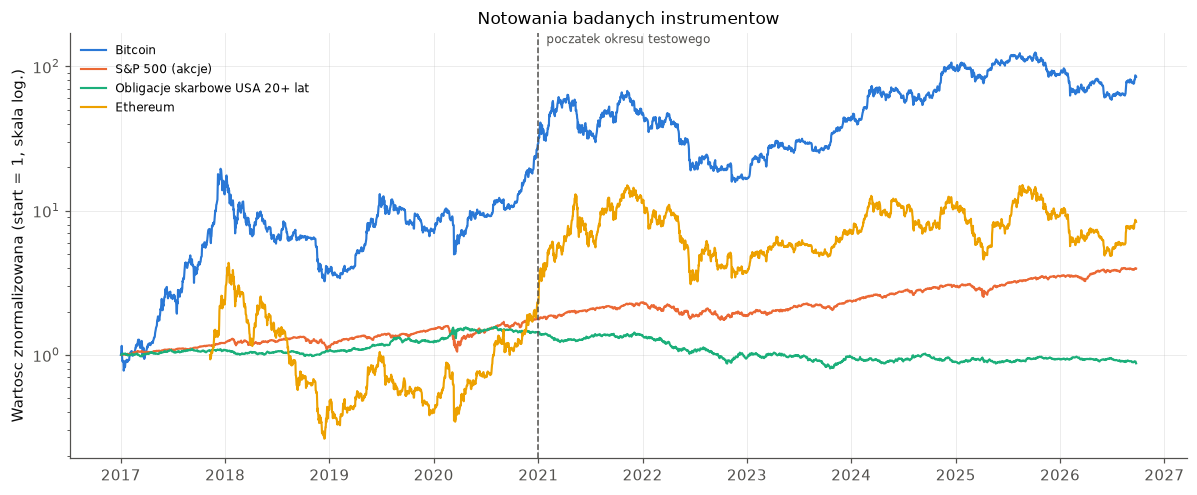

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for tk in list(TICKERS) + [TICKER_WERYFIKACYJNY]:
    c = raw_data[tk]['Close'].dropna()
    ax.plot(c.index, c / c.iloc[0], label=TICKERS.get(tk, 'Ethereum'), color=KOLORY[tk], linewidth=1.4)
ax.set_yscale('log')
ax.axvline(OOS_START, color=KOLORY['pasywnie'], linestyle='--', linewidth=1)
ax.text(OOS_START, ax.get_ylim()[1], '  poczatek okresu testowego', va='top', fontsize=8,
        color=KOLORY['pasywnie'])
ax.set_ylabel('Wartosc znormalizowana (start = 1, skala log.)')
ax.set_title('Notowania badanych instrumentow')
ax.legend(loc='upper left')
plt.tight_layout()
zapisz_rys('1_1_ceny_instrumentow')
plt.show()

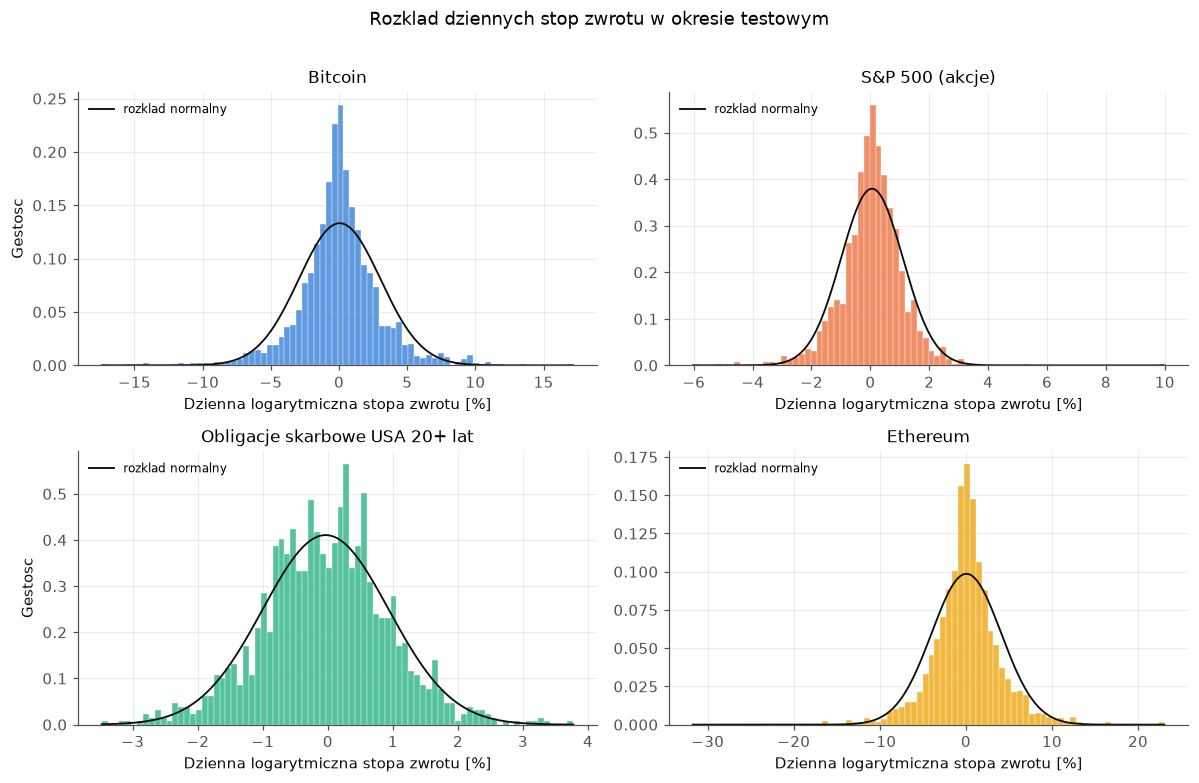

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, tk in zip(axes.flat, list(TICKERS) + [TICKER_WERYFIKACYJNY]):
    keys = [(t, m) for (t, m) in wf_results if t == tk]
    if not keys:
        ax.set_visible(False)
        continue
    idx = wf_results[keys[0]]['oos'].index
    r = (np.log(raw_data[tk]['Close'] / raw_data[tk]['Close'].shift(1)).reindex(idx).dropna() * 100)
    ax.hist(r, bins=80, density=True, color=KOLORY[tk], alpha=0.75, edgecolor='white', linewidth=0.3)
    x = np.linspace(r.min(), r.max(), 400)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), color=KOLORY['tekst'], linewidth=1.2,
            label='rozklad normalny')
    ax.set_title(TICKERS.get(tk, 'Ethereum'))
    ax.set_xlabel('Dzienna logarytmiczna stopa zwrotu [%]')
    ax.legend(loc='upper left')
for ax in axes[:, 0]:
    ax.set_ylabel('Gestosc')
plt.suptitle('Rozklad dziennych stop zwrotu w okresie testowym', y=1.01)
plt.tight_layout()
zapisz_rys('1_2_rozklady_zwrotow')
plt.show()

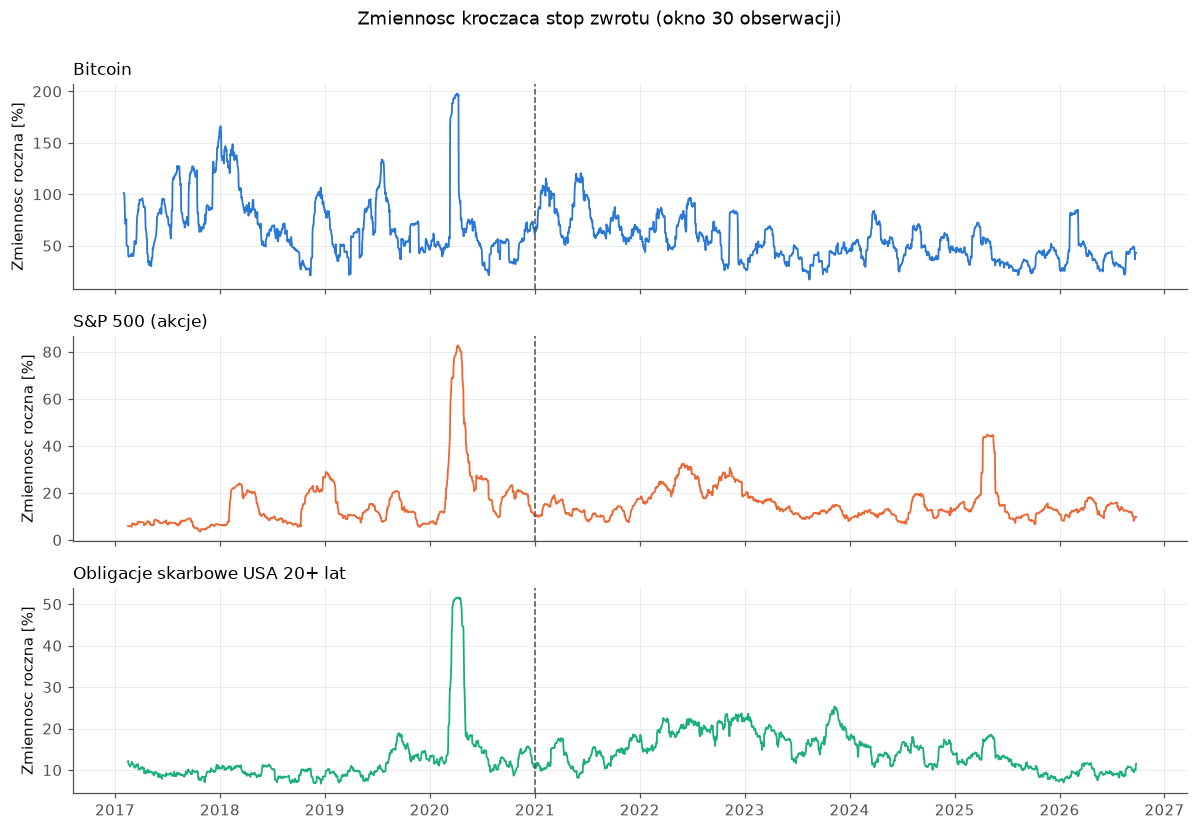

In [8]:
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(11, 7.5), sharex=True)
for ax, tk in zip(axes, TICKERS):
    c = raw_data[tk]['Close']
    vol = np.log(c / c.shift(1)).rolling(30).std() * np.sqrt(FREQ_MAP[tk]) * 100
    ax.plot(vol.index, vol.values, color=KOLORY[tk], linewidth=1.2)
    ax.axvline(OOS_START, color=KOLORY['pasywnie'], linestyle='--', linewidth=1)
    ax.set_title(TICKERS[tk], loc='left')
    ax.set_ylabel('Zmiennosc roczna [%]')
plt.suptitle('Zmiennosc kroczaca stop zwrotu (okno 30 obserwacji)', y=1.0)
plt.tight_layout()
zapisz_rys('1_3_zmiennosc_kroczaca')
plt.show()

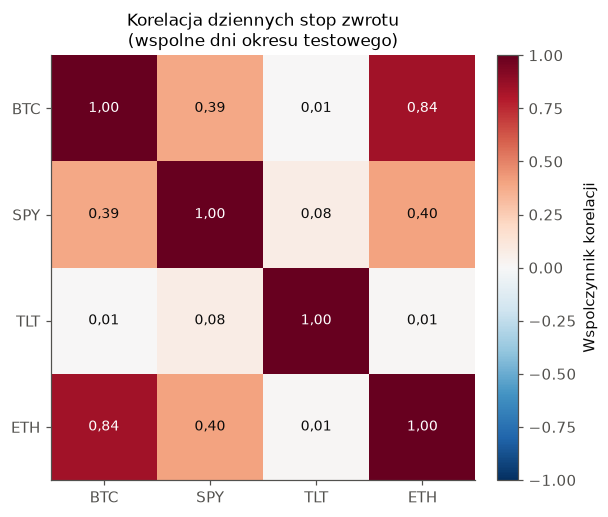

In [9]:
_skroty = {'BTC-USD': 'BTC', 'SPY': 'SPY', 'TLT': 'TLT', 'ETH-USD': 'ETH'}
_idx_w = None
for tk in list(TICKERS) + [TICKER_WERYFIKACYJNY]:
    keys = [(t, m) for (t, m) in wf_results if t == tk]
    if keys:
        i = wf_results[keys[0]]['oos'].index
        _idx_w = i if _idx_w is None else _idx_w.intersection(i)
_zw = pd.DataFrame({_skroty[tk]: np.log(raw_data[tk]['Close'] / raw_data[tk]['Close'].shift(1))
                    for tk in list(TICKERS) + [TICKER_WERYFIKACYJNY]}).reindex(_idx_w).dropna()
_kor = _zw.corr()

fig, ax = plt.subplots(figsize=(5.8, 4.8))
im = ax.imshow(_kor.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(_kor)))
ax.set_xticklabels(_kor.columns)
ax.set_yticks(range(len(_kor)))
ax.set_yticklabels(_kor.index)
ax.grid(False)
for i in range(len(_kor)):
    for j in range(len(_kor)):
        v = _kor.values[i, j]
        ax.text(j, i, f'{v:.2f}'.replace('.', ','), ha='center', va='center', fontsize=9,
                color='white' if abs(v) > 0.6 else KOLORY['tekst'])
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Wspolczynnik korelacji')
ax.set_title('Korelacja dziennych stop zwrotu\n(wspolne dni okresu testowego)')
plt.tight_layout()
zapisz_rys('1_4_korelacje_zwrotow')
plt.show()

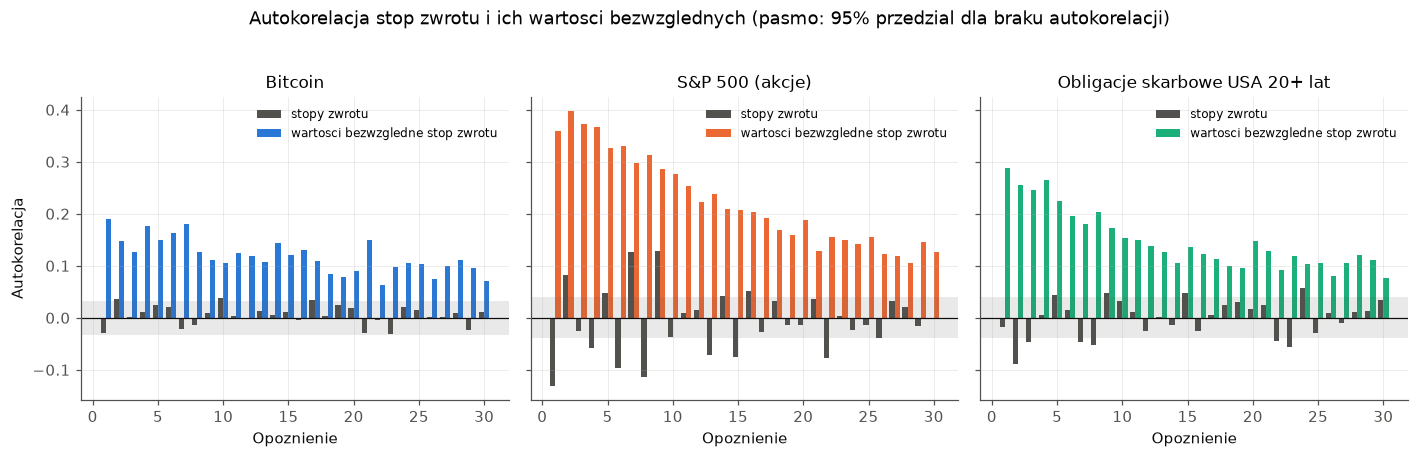

In [10]:
def _acf(x, maxlag):
    x = np.asarray(x, dtype=float) - np.mean(x)
    d = np.dot(x, x)
    return np.array([np.dot(x[:-k], x[k:]) / d for k in range(1, maxlag + 1)])


LAGI = 30
fig, axes = plt.subplots(1, len(TICKERS), figsize=(13, 4.0), sharey=True)
for ax, tk in zip(axes, TICKERS):
    r = np.log(raw_data[tk]['Close'] / raw_data[tk]['Close'].shift(1)).dropna().values
    lags = np.arange(1, LAGI + 1)
    ax.bar(lags - 0.2, _acf(r, LAGI), width=0.4, color=KOLORY['pasywnie'], label='stopy zwrotu')
    ax.bar(lags + 0.2, _acf(np.abs(r), LAGI), width=0.4, color=KOLORY[tk],
           label='wartosci bezwzgledne stop zwrotu')
    pasmo = 1.96 / np.sqrt(len(r))
    ax.axhspan(-pasmo, pasmo, color=KOLORY['pasywnie'], alpha=0.12, linewidth=0)
    ax.axhline(0, color=KOLORY['tekst'], linewidth=0.8)
    ax.set_title(TICKERS[tk])
    ax.set_xlabel('Opoznienie')
    ax.legend(loc='upper right')
axes[0].set_ylabel('Autokorelacja')
plt.suptitle('Autokorelacja stop zwrotu i ich wartosci bezwzglednych '
             '(pasmo: 95% przedzial dla braku autokorelacji)', y=1.03)
plt.tight_layout()
zapisz_rys('1_5_autokorelacja')
plt.show()

## 1.3. Stacjonarność zmiennych objaśniających

Test rozszerzony Dickeya-Fullera dla wszystkich zmiennych objaśniających. Hipoteza zerowa zakłada
obecność pierwiastka jednostkowego, czyli niestacjonarność szeregu.

Uczenie modelu na szeregu niestacjonarnym powoduje, że rozkład zmiennej w okresie testowym może
leżeć poza zakresem obserwowanym w treningu, a standaryzacja wyznaczona na zbiorze treningowym
przestaje być adekwatna. Konsekwencje takiej specyfikacji dla wyniku badania są przedmiotem
sekcji 5.1.

Z zestawienia wyłączone zostały zmienne kalendarzowe, które są funkcjami deterministycznymi —
dla szeregu okresowego o znanej postaci test pierwiastka jednostkowego nie ma interpretacji.
Pełna tabela dla wszystkich zmiennych znajduje się w aneksie A6.

In [11]:
adf_all = pd.DataFrame()
if OPT['statsmodels']:
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for tk in TICKERS:
            d = feature_data[tk]
            for f in FEATURES_BY_TICKER[tk]:
                if f in ZMIENNE_KALENDARZOWE:
                    continue
                out = adf_summary(d[f], f)
                if out:
                    out['Instrument'], out['Grupa'] = TICKERS[tk], grupa_zmiennej(f)
                    rows.append(out)
    adf_all = pd.DataFrame(rows)

    print('Udzial zmiennych stacjonarnych (poziom istotnosci 5%):\n')
    display(adf_all.pivot_table(index='Instrument', columns='Grupa',
                                values='Stacjonarna', aggfunc='mean').round(3))

    nies = adf_all[~adf_all['Stacjonarna']].sort_values('p-value', ascending=False)
    print(f'\nZmienne niestacjonarne: {len(nies)} z {len(adf_all)} '
          f'({len(nies)/max(len(adf_all),1):.1%})\n')
    if len(nies):
        display(nies[['Instrument', 'Zmienna', 'Grupa', 'ADF', 'p-value']].round(4)
                .reset_index(drop=True))

Udzial zmiennych stacjonarnych (poziom istotnosci 5%):



Grupa,rynkowe i makroekonomiczne,sieciowe i sentyment,techniczne
Instrument,,,
Bitcoin,1.0000,1.0000,1.0000
Obligacje skarbowe USA 20+ lat,1.0000,NaN,0.9290
S&P 500 (akcje),1.0000,NaN,1.0000



Zmienne niestacjonarne: 2 z 267 (0.7%)



,Instrument,Zmienna,Grupa,ADF,p-value
0,Obligacje skarbowe USA 20+ lat,drawdown_252,techniczne,-2.4270,0.1342
1,Obligacje skarbowe USA 20+ lat,price_sma_200_ratio,techniczne,-2.6786,0.0778


Warunek stacjonarności spełnia niemal cały zbiór. Zmienne opisujące poziomy stóp procentowych
i spreadów kredytowych zostały wcześniej zastąpione ich pierwszymi różnicami właśnie na podstawie
tego testu. Pozostałe dwa przypadki dotyczą wskaźnika obsunięcia i odchylenia od średniej
długookresowej dla obligacji, gdzie brak stacjonarności wynika z charakteru badanego okresu —
trwałej bessy na rynku długu, w której obie te miary nie powracają do poziomów wyjściowych.
Oba wyniki są graniczne i zmienne zostały zachowane.

Odrębnym zagadnieniem jest skala wariancji. Wskaźnik MACD w postaci nominalnej pozostaje
stacjonarny w sensie testu ADF, ponieważ stanowi różnicę dwóch średnich wykładniczych
i oscyluje wokół zera. Jego wariancja jest jednak proporcjonalna do poziomu ceny: przy bitcoinie
wycenianym na dwadzieścia tysięcy dolarów amplituda wynosi rząd setek, przy stu tysiącach rząd
tysięcy. Podzielenie przez cenę usuwa tę zależność, a uzasadnieniem transformacji jest zatem
heteroskedastyczność, nie niestacjonarność.

---

# 2. Procedura testowa

Model uczy się na danych historycznych, prognozuje kolejne 42 sesje, po czym okno treningowe
zostaje rozszerzone o nowe obserwacje i procedura się powtarza. Daje to od 34 do 49 rozłącznych
okien prognostycznych w zależności od instrumentu.

Zabezpieczenia przed przeciekiem informacji:

1. Standaryzacja zmiennych wyznaczana wyłącznie na zbiorze treningowym.
2. Bufor 50 sesji między końcem okna treningowego a początkiem testowego. Zmienne wykorzystują
   okna do 252 sesji, a zmienna objaśniana sięga w przód do H sesji, wobec czego obserwacje
   na styku obu zbiorów są skorelowane.
3. Hiperparametry dobierane na wydzielonym zbiorze walidacyjnym stanowiącym ostatnie 20% okna
   treningowego, również oddzielonym buforem. Okno testowe nie jest wykorzystywane na żadnym
   etapie decyzyjnym.

Pętla ucząca zapisuje wyłącznie prawdopodobieństwa przypisane przez modele w oknach testowych.
Reguły inwestycyjne konstruowane są następnie na ich podstawie, co umożliwia porównanie wielu
wariantów bez ponownego uczenia.

In [12]:
rows = []
for (tk, mode), res in wf_results.items():
    if mode not in ZADANIA_GLOWNE:
        continue
    oos = res['oos']
    rows.append({'Instrument': TICKERS.get(tk, 'Ethereum'), 'Zadanie': NAZWA_ZADANIA[mode],
                 'Okna prognostyczne': res['n_splits'], 'Dni testowe': len(oos),
                 'Lata': len(oos) / FREQ_MAP[tk],
                 'Od': oos.index.min().date(), 'Do': oos.index.max().date()})
okna_testowe = pd.DataFrame(rows).sort_values(['Instrument', 'Zadanie']).reset_index(drop=True)
display(okna_testowe)

,Instrument,Zadanie,Okna prognostyczne,Dni testowe,Lata,Od,Do
0,Bitcoin,kierunek zmiany (D+1),49,2058,5.6384,2021-01-01,2026-08-20
1,Bitcoin,ryzyko duzego spadku,49,2058,5.6384,2021-01-01,2026-08-20
2,Ethereum,kierunek zmiany (D+1),49,2058,5.6384,2021-01-01,2026-08-20
3,Ethereum,ryzyko duzego spadku,49,2058,5.6384,2021-01-01,2026-08-20
4,Obligacje skarbowe USA 20+ lat,kierunek zmiany (D+1),34,1428,5.6667,2021-01-04,2026-09-10
5,Obligacje skarbowe USA 20+ lat,ryzyko duzego spadku,34,1428,5.6667,2021-01-04,2026-09-10
6,S&P 500 (akcje),kierunek zmiany (D+1),34,1428,5.6667,2021-01-04,2026-09-10
7,S&P 500 (akcje),ryzyko duzego spadku,34,1428,5.6667,2021-01-04,2026-09-10


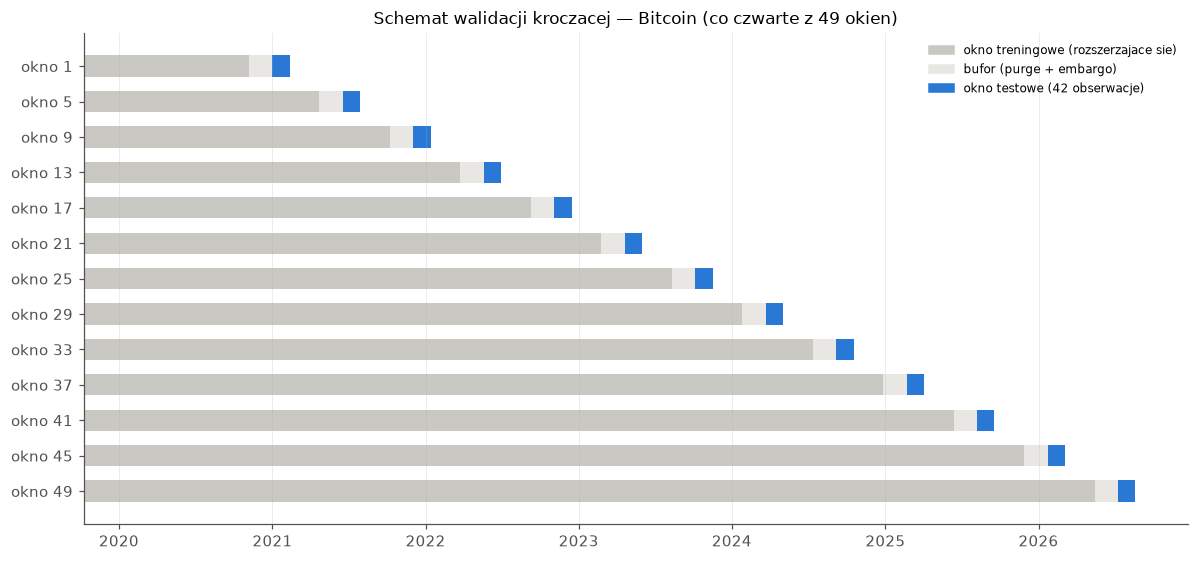

In [13]:
_dd_w, _ = prepare_dataset(GLOWNY_TK, GLOWNE_ZADANIE)
_splits_w = walk_forward_splits(_dd_w.index, OOS_START, TEST_WINDOW, STEP, mode=WF_MODE,
                                rolling_train=ROLLING_TRAIN,
                                purge=max(PURGE, TARGET_HORIZON[GLOWNE_ZADANIE] + 1), embargo=EMBARGO)
_pokaz = sorted(set(list(range(0, len(_splits_w), 4)) + [len(_splits_w) - 1]))
_d = mdates.date2num(_dd_w.index.to_pydatetime())

fig, ax = plt.subplots(figsize=(11, 5.2))
for j, k in enumerate(_pokaz):
    tr, te = _splits_w[k]
    ax.barh(j, _d[tr[-1]] - _d[tr[0]], left=_d[tr[0]], height=0.6, color='#c9c8c3')
    ax.barh(j, _d[te[0]] - _d[tr[-1]], left=_d[tr[-1]], height=0.6, color='#e8e7e3')
    ax.barh(j, _d[te[-1]] - _d[te[0]], left=_d[te[0]], height=0.6, color=KOLORY['procedura'])
ax.set_yticks(range(len(_pokaz)))
ax.set_yticklabels([f'okno {k + 1}' for k in _pokaz])
ax.invert_yaxis()
ax.xaxis_date()
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color='#c9c8c3', label='okno treningowe (rozszerzajace sie)'),
                   Patch(color='#e8e7e3', label='bufor (purge + embargo)'),
                   Patch(color=KOLORY['procedura'], label='okno testowe (42 obserwacje)')],
          loc='upper right')
ax.set_title(f'Schemat walidacji kroczacej — {TICKERS[GLOWNY_TK]} '
             f'(co czwarte z {len(_splits_w)} okien)')
plt.tight_layout()
zapisz_rys('2_1_walidacja_kroczaca')
plt.show()

## 2.1. Zadania prognostyczne i reguła inwestycyjna

W części głównej porównywane są dwa sposoby sformułowania zmiennej objaśnianej. **Kierunek zmiany
ceny** oznacza pytanie, czy stopa zwrotu w kolejnej sesji będzie dodatnia. **Ryzyko dużego
spadku** oznacza pytanie, czy strata w kolejnej sesji przekroczy półtorakrotność bieżącego
odchylenia standardowego dziennych stóp zwrotu. Stopa zwrotu wykorzystywana w symulacji jest
w obu przypadkach identyczna — zmienia się wyłącznie to, czego model się uczy. Dwa dalsze
sformułowania znajdują się w aneksie A1.

Prawdopodobieństwo przekształcane jest w pozycję regułą o trzech elementach: strefie neutralnej
(wejście powyżej progu, wyjście poniżej progu niższego), minimalnym czasie utrzymania pozycji oraz
kontroli zmienności, w której wielkość pozycji jest odwrotnie proporcjonalna do bieżącej zmienności
instrumentu. Dwa pierwsze elementy ograniczają liczbę transakcji, trzeci wykorzystuje własność,
zgodnie z którą zmienność — odmiennie niż kierunek zmiany ceny — wykazuje istotną autokorelację.

**Procedura główna** nie ustala parametrów tej reguły z góry. Zbiór kandydatów obejmuje
192 kombinacje parametrów — cztery progi wejścia, trzy szerokości strefy neutralnej, cztery długości
minimalnego utrzymania pozycji i cztery warianty kontroli zmienności — stosowane do prognoz modelu
XGBoost. Dla każdego okna testowego procedura:

1. ocenia wszystkie warianty według wskaźnika Sharpe'a uzyskanego na oknach wcześniejszych,
2. wybiera *n* najlepszych i jako pozycję przyjmuje średnią ich wskazań,
3. liczbę *n* wybiera spośród wartości 1, 5, 10, 20, 50 oraz wszystkich wariantów — również według
   wyników, jakie procedura z każdą z tych wartości uzyskała na oknach wcześniejszych.

Żaden element procedury nie korzysta z okna, dla którego podejmowana jest decyzja, ani z okien
późniejszych. W trzech pierwszych oknach, dla których brak jeszcze historii ocen, pozycja jest
średnią wszystkich wariantów. Liczba *n* jest wybierana od chwili, gdy dostępne są wyniki co
najmniej trzech kolejnych okien; do tego czasu przyjmowana jest wartość obejmująca wszystkie
warianty, a przy równych ocenach wybierana jest wartość większa.

Źródłem prognoz jest XGBoost, czyli jedyny model, którego zdolność prognostyczna na bitcoinie
pozostaje istotna po korekcie na liczbę przeprowadzonych testów (sekcja 3). Rozważono również dwa
warianty obejmujące wszystkie trzy modele: wybór modelu w ramach procedury, ze zbiorem
576 kandydatów, oraz uśrednienie prognoz modeli przed zastosowaniem reguły. Porównanie trzech
wariantów przedstawiono w sekcji 5.6. Wariant główny wybrano po tym porównaniu, co stanowi jeden
z przykładów wrażliwości wyniku na decyzje metodologiczne, badanej w ramach hipotezy 3.

Jako punkt odniesienia zachowana została **konfiguracja stała**: model XGBoost, progi 0,55 i 0,45,
pięć sesji minimalnego utrzymania pozycji i docelowa zmienność 30%. Parametry te ustalono na
wcześniejszym etapie badania i nie były korygowane po uzyskaniu ostatecznych wyników; ich położenie
w rozkładzie wszystkich kombinacji jest przedmiotem sekcji 5.2. Pozostałe warianty reguły
inwestycyjnej oraz wrażliwość procedury głównej na liczbę uśrednianych wariantów znajdują się
w aneksach A2 i A3.

Koszt transakcyjny wynosi 0,1% od zmiany pozycji, a kapitał utrzymywany poza rynkiem jest
oprocentowany stopą bonów skarbowych. Strategie aktywne spędzają poza rynkiem znaczną część
okresu testowego, a w latach 2022–2024 bony dawały 4–5% rocznie, wobec czego przyjęcie zerowej
stopy wolnej od ryzyka systematycznie zaniżałoby ich wynik.

Wskaźnik Sortino liczony jest z odchyleniem poniżej stopy docelowej równej bieżącej stopie wolnej
od ryzyka: kwadraty ujemnych nadwyżek są uśredniane po wszystkich obserwacjach, a obserwacje
powyżej stopy docelowej wnoszą zero.

In [14]:
KONFIGURACJA_STALA = STRATEGIA_GLOWNA
MODELE_PROCEDURY = MODELS
N_KROCZACE = (1, 5, 10, 20, 50, None)
MIN_OKIEN = 3

WARIANTY_PROCEDURY = {
    'wybor':   'wybor modelu z puli trzech modeli',
    'srednia': 'srednia prognoz trzech modeli',
    'xgboost': 'wylacznie XGBoost',
}
WARIANT_PROCEDURY = 'xgboost'

if '_compute_metrics_bazowe' not in globals():
    _compute_metrics_bazowe = compute_metrics


def compute_metrics(returns, positions=None, turnover=None, ticker=None,
                    asset_returns=None, label=''):
    out = _compute_metrics_bazowe(returns, positions, turnover, ticker, asset_returns, label)
    r = pd.Series(returns).dropna()
    if len(r):
        freq = FREQ_MAP.get(ticker, 252)
        ex = r - rf_daily_for(r.index, freq)
        dd = np.sqrt(np.mean(np.minimum(ex.values, 0.0) ** 2)) * np.sqrt(freq)
        out['Sortino'] = (ex.mean() * freq) / dd if dd > 0 else np.nan
    return out


_PAMIEC_PROCEDURY = {}


def _dostepne_modele(oos, modele=None):
    modele = MODELE_PROCEDURY if modele is None else modele
    return [m for m in modele if f'proba_{m}' in oos.columns
            and oos[f'proba_{m}'].nunique(dropna=True) > 1]


def _sharpe_wierszy(R, maska):
    m, sd = R[:, maska].mean(axis=1), R[:, maska].std(axis=1)
    return np.where(sd > 1e-12, m / sd, -np.inf)


def _procedura(oos, ticker, modele):
    modele = _dostepne_modele(oos, modele)
    klucz = (ticker, tuple(modele), len(oos), str(oos.index[0]), str(oos.index[-1]),
             float(np.nansum(oos[[f'proba_{m}' for m in modele]].values)))
    if klucz in _PAMIEC_PROCEDURY:
        return _PAMIEC_PROCEDURY[klucz]

    rf = rf_daily_for(oos.index, FREQ_MAP[ticker])
    P, R, M = [], [], []
    for m in modele:
        for cfg in siatka_konfiguracji():
            pos = build_positions(oos, ticker, f'proba_{m}', cfg)
            r, _, _ = backtest(pos, oos, ticker)
            P.append(pos.values)
            R.append((r - rf).values)
            M.append(m)
    P, R, M = np.array(P), np.array(R), np.array(M)
    K = len(P)

    folds = np.asarray(oos['fold'].values)
    okna = sorted(pd.unique(folds))

    warianty, wybrane = {}, {}
    for n in N_KROCZACE:
        k = K if n is None else min(n, K)
        out, sel = np.zeros(len(oos)), {}
        for i, f in enumerate(okna):
            teraz, hist = folds == f, folds < f
            if i < MIN_OKIEN or hist.sum() < 60:
                idx = np.arange(K)
            else:
                idx = np.argsort(_sharpe_wierszy(R, hist))[::-1][:k]
            out[teraz] = P[np.ix_(idx, teraz)].mean(axis=0)
            sel[f] = idx
        warianty[n] = pd.Series(np.clip(out, 0.0, MAX_LEVERAGE), index=oos.index)
        wybrane[n] = sel

    RW = {n: (backtest(p, oos, ticker)[0] - rf).values for n, p in warianty.items()}
    kolejnosc = sorted(N_KROCZACE, key=lambda n: -(K if n is None else n))

    pos = np.zeros(len(oos))
    n_okna, udzialy = {}, []
    for i, f in enumerate(okna):
        teraz = folds == f
        ocenione = np.isin(folds, okna[MIN_OKIEN:i])
        if i < 2 * MIN_OKIEN or ocenione.sum() < 60:
            n_wyb = None
        else:
            ocena = {}
            for n in kolejnosc:
                x = RW[n][ocenione]
                ocena[n] = x.mean() / x.std() if x.std() > 1e-12 else -np.inf
            n_wyb = max(kolejnosc, key=lambda n: ocena[n])
        pos[teraz] = warianty[n_wyb].values[teraz]
        n_okna[f] = K if n_wyb is None else n_wyb
        wsk = M[wybrane[n_wyb][f]]
        udzialy.append({'Okno': f, **{MODEL_LABEL.get(m, 'Srednia modeli'): float(np.mean(wsk == m))
                                      for m in modele}})

    wynik = dict(pos=pd.Series(np.clip(pos, 0.0, MAX_LEVERAGE), index=oos.index),
                 n_wybrane=pd.Series(n_okna, name='Liczba usrednianych wariantow'),
                 udzial_modeli=pd.DataFrame(udzialy).set_index('Okno'),
                 warianty=warianty, liczba_kandydatow=K, modele=modele,
                 okna_rozruchu=2 * MIN_OKIEN)
    _PAMIEC_PROCEDURY[klucz] = wynik
    return wynik


def procedura_glowna(oos, ticker, modele=None, wariant=None):
    wariant = WARIANT_PROCEDURY if wariant is None else wariant
    if modele is None and wariant == 'srednia':
        dost = _dostepne_modele(oos)
        oos = oos.assign(proba_SREDNIA=oos[[f'proba_{m}' for m in dost]].mean(axis=1))
        modele = ['SREDNIA']
    elif modele is None and wariant == 'xgboost':
        modele = ['XGB']
    return _procedura(oos, ticker, modele)


print(f'Procedura glowna — wariant: {WARIANTY_PROCEDURY[WARIANT_PROCEDURY]}; '
      f'{len(siatka_konfiguracji())} konfiguracji na model; liczba usrednianych wariantow '
      f'wybierana z {[n if n else "wszystkie" for n in N_KROCZACE]}.')

Procedura glowna — wariant: wylacznie XGBoost; 192 konfiguracji na model; liczba usrednianych wariantow wybierana z [1, 5, 10, 20, 50, 'wszystkie'].


In [15]:
strategie = {}
for (tk, mode), res in wf_results.items():
    if mode not in ZADANIA_GLOWNE:
        continue
    oos = res['oos']
    strategie[(tk, mode, 'Kup i trzymaj')] = buy_and_hold(oos, tk)
    strategie[(tk, mode, 'Filtr SMA200')] = sma_benchmark(oos, tk, 200)
    for m in MODELS:
        for etykieta, cfg in [('regula prosta', STRATEGIA_PROSTA),
                              ('konfiguracja stala', KONFIGURACJA_STALA)]:
            pos = build_positions(oos, tk, f'proba_{m}', cfg)
            strategie[(tk, mode, f'{MODEL_LABEL[m]} — {etykieta}')] = backtest(pos, oos, tk)
    strategie[(tk, mode, 'Procedura glowna')] = backtest(procedura_glowna(oos, tk)['pos'], oos, tk)

rows = []
for (tk, mode, nazwa), (r, p, t) in strategie.items():
    row = compute_metrics(r, p, t, ticker=tk,
                          asset_returns=wf_results[(tk, mode)]['oos']['next_return'], label=nazwa)
    row['Instrument'], row['Zadanie'] = TICKERS.get(tk, 'Ethereum'), NAZWA_ZADANIA[mode]
    row['_tk'], row['_mode'] = tk, mode
    rows.append(row)
metryki_pelne = pd.DataFrame(rows)

KOL = ['Strategia', 'Zwrot', 'CAGR', 'Max obsuniecie', 'Calmar', 'Sortino', 'Sharpe',
       'Zmiennosc', 'Zaangazowanie', 'Rotacja']
print(f'Policzono {len(metryki_pelne)} kombinacji strategii '
      f'(pelne zestawienie w aneksie A5).')

Policzono 72 kombinacji strategii (pelne zestawienie w aneksie A5).


---

# 3. Hipoteza 1: zdolność prognostyczna zależy od rynku i od sformułowania zadania

Procedura, zbiór zmiennych i modele są identyczne dla wszystkich kombinacji. Zmienia się wyłącznie
rynek oraz to, o co pytany jest model.

Miarą zdolności prognostycznej jest pole pod krzywą ROC, gdzie 0,50 oznacza brak zdolności
rozróżniania przypadków. Test Pesarana-Timmermanna weryfikuje, czy zgodność prognozy z realizacją
przewyższa poziom wynikający z samych częstości brzegowych, czyli czy prognoza i realizacja są
statystycznie niezależne.

In [16]:
rows = []
for (tk, mode), res in wf_results.items():
    if mode not in ZADANIA_GLOWNE or tk == TICKER_WERYFIKACYJNY:
        continue
    oos = res['oos']
    y = oos['y_true'].values
    for m in MODELS:
        p = oos[f'proba_{m}'].values
        yhat = (p > 0.5).astype(int)
        pt = pesaran_timmermann(y, yhat)
        rows.append({
            'Instrument': TICKERS[tk], 'Zadanie': NAZWA_ZADANIA[mode], 'Model': MODEL_LABEL[m],
            'Trafnosc': accuracy_score(y, yhat),
            'Trafnosc zrownowazona': balanced_accuracy_score(y, yhat),
            'AUC': roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan,
            'Udzial klasy dodatniej': float(np.mean(y)),
            'Test PT (p)': pt['p_value'],
            'Istotne (5%)': 'tak' if (np.isfinite(pt['p_value']) and pt['p_value'] < 0.05) else 'nie',
        })
klasyfikacja = pd.DataFrame(rows)
display(klasyfikacja.round(4))

_n_testow = len(klasyfikacja)
_prog_bonf = 0.05 / _n_testow
_ile = int((klasyfikacja['Test PT (p)'] < _prog_bonf).sum())
print(f'\nLiczba testow w zestawieniu: {_n_testow}. Prog po korekcie Bonferroniego: '
      f'{_prog_bonf:.4f}.')
print(f'Wynikow istotnych po korekcie: {_ile}.')
if _ile:
    display(klasyfikacja[klasyfikacja['Test PT (p)'] < _prog_bonf]
            [['Instrument', 'Zadanie', 'Model', 'AUC', 'Test PT (p)']].round(4)
            .reset_index(drop=True))

,Instrument,Zadanie,Model,Trafnosc,Trafnosc zrownowazona,AUC,Udzial klasy dodatniej,Test PT (p),Istotne (5%)
0,Bitcoin,kierunek zmiany (D+1),Regresja logistyczna,0.5034,0.5037,0.5076,0.4971,0.3669,nie
1,Bitcoin,kierunek zmiany (D+1),XGBoost,0.5190,0.5193,0.5264,0.4971,0.0391,tak
2,Bitcoin,kierunek zmiany (D+1),LSTM,0.5180,0.5179,0.5276,0.4971,0.0524,nie
3,Bitcoin,ryzyko duzego spadku,Regresja logistyczna,0.8256,0.5318,0.5731,0.9349,0.0185,tak
4,Bitcoin,ryzyko duzego spadku,XGBoost,0.5126,0.5762,0.5860,0.9349,0.0003,tak
5,Bitcoin,ryzyko duzego spadku,LSTM,0.8319,0.4935,0.5147,0.9349,0.6747,nie
6,S&P 500 (akcje),kierunek zmiany (D+1),Regresja logistyczna,0.5063,0.4943,0.4884,0.5441,0.6730,nie
7,S&P 500 (akcje),kierunek zmiany (D+1),XGBoost,0.5238,0.5136,0.5076,0.5441,0.1461,nie
8,S&P 500 (akcje),kierunek zmiany (D+1),LSTM,0.5056,0.5025,0.5081,0.5441,0.4260,nie
9,S&P 500 (akcje),ryzyko duzego spadku,Regresja logistyczna,0.7752,0.5510,0.5733,0.9272,0.0057,tak



Liczba testow w zestawieniu: 18. Prog po korekcie Bonferroniego: 0.0028.
Wynikow istotnych po korekcie: 1.


,Instrument,Zadanie,Model,AUC,Test PT (p)
0,Bitcoin,ryzyko duzego spadku,XGBoost,0.5860,0.0003


Zdolnosc prognostyczna (AUC) w zaleznosci od sformulowania zadania



Zadanie                                              kierunek zmiany (D+1)  ryzyko duzego spadku  Roznica
Instrument                     Model                                                                     
Bitcoin                        LSTM                                 0.5276                0.5147  -0.0129
                               Regresja logistyczna                 0.5076                0.5731   0.0655
                               XGBoost                              0.5264                0.5860   0.0596
Obligacje skarbowe USA 20+ lat LSTM                                 0.5246                0.5111  -0.0136
                               Regresja logistyczna                 0.5214                0.5558   0.0344
                               XGBoost                              0.5324                0.5234  -0.0090
S&P 500 (akcje)                LSTM                                 0.5081                0.5239   0.0158
                               Regresja logistyczna                 0.4884                0.5733   0.0850
                               XGBoost                              0.5076                0.5848   0.0772

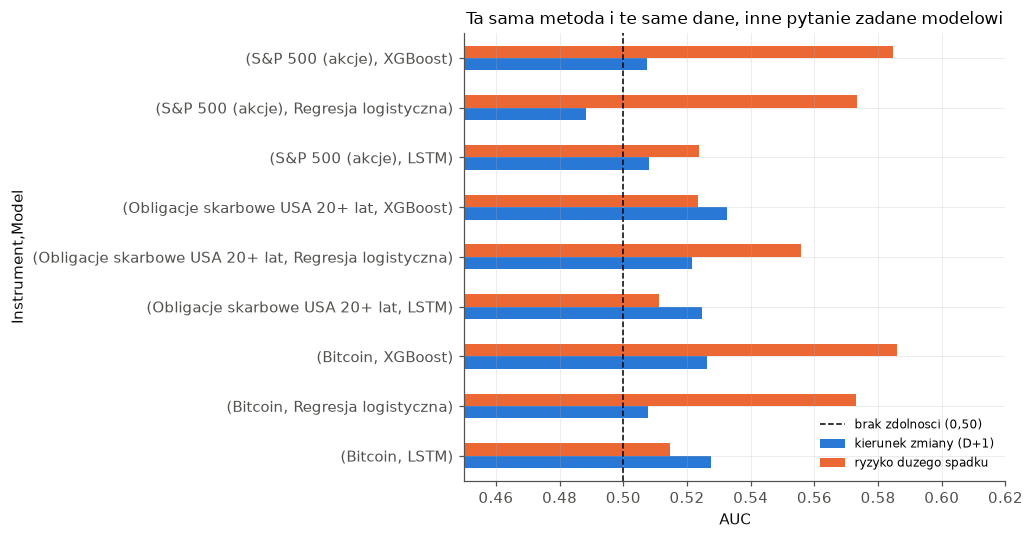

In [17]:
por = klasyfikacja.pivot_table(index=['Instrument', 'Model'], columns='Zadanie', values='AUC')
kol_kier = [c for c in por.columns if 'kierunek' in c][0]
kol_ryz = [c for c in por.columns if 'ryzyko' in c][0]
por['Roznica'] = por[kol_ryz] - por[kol_kier]
roznica_auc = por
print('Zdolnosc prognostyczna (AUC) w zaleznosci od sformulowania zadania\n')
display(roznica_auc.round(4))

fig, ax = plt.subplots(figsize=(9.5, 5.0))
roznica_auc[[kol_kier, kol_ryz]].plot(kind='barh', ax=ax)
ax.axvline(0.5, color='black', linestyle='--', linewidth=1, label='brak zdolnosci (0,50)')
ax.set_xlim(0.45, 0.62)
ax.set_xlabel('AUC')
ax.set_title('Ta sama metoda i te same dane, inne pytanie zadane modelowi')
ax.legend(fontsize=8)
plt.tight_layout()
zapisz_rys('3_1_auc_wg_zadania')
plt.show()

## 3.1. Weryfikacja na drugim instrumencie tej samej klasy

Wynik uzyskany dla bitcoina opiera się na jednym instrumencie. Aby ocenić, czy dotyczy on szerzej
rynku kryptowalut, tę samą procedurę zastosowano do Ethereum. Zbiór zmiennych obejmuje te same
zmienne techniczne i zewnętrzne, z wyłączeniem kursu ETH, oraz wskaźnik nastrojów rynku
kryptowalut i stawki finansowania kontraktów wieczystych ETHUSDT. Dane sieciowe bitcoina zostały
pominięte, aby nie przenosić informacji specyficznej dla jednego aktywa.

In [18]:
ETH = TICKER_WERYFIKACYJNY
rows = []
for mode in ZADANIA_GLOWNE:
    if (ETH, mode) not in wf_results:
        continue
    oos = wf_results[(ETH, mode)]['oos']
    y = oos['y_true'].values
    bh = buy_and_hold(oos, ETH)
    m_bh = compute_metrics(bh[0], bh[1], bh[2], ticker=ETH, label='')
    for m in MODELS:
        pos = build_positions(oos, ETH, f'proba_{m}', KONFIGURACJA_STALA)
        r, p_, t_ = backtest(pos, oos, ETH)
        met = compute_metrics(r, p_, t_, ticker=ETH, asset_returns=oos['next_return'], label='')
        pt = pesaran_timmermann(y, (oos[f'proba_{m}'].values > 0.5).astype(int))
        rows.append({
            'Zadanie': NAZWA_ZADANIA[mode], 'Model': MODEL_LABEL[m],
            'AUC': roc_auc_score(y, oos[f'proba_{m}'].values) if len(np.unique(y)) > 1 else np.nan,
            'Test PT (p)': pt['p_value'],
            'Sharpe modelu': met['Sharpe'], 'Sharpe pasywnie': m_bh['Sharpe'],
            'Obsuniecie modelu': met['Max obsuniecie'],
            'Obsuniecie pasywnie': m_bh['Max obsuniecie'],
            'Zaangazowanie': met['Zaangazowanie']})
ethereum = pd.DataFrame(rows)
print('Ethereum — identyczna procedura i ten sam okres testowy co dla bitcoina '
      '(wskazniki inwestycyjne dla konfiguracji stalej)\n')
display(ethereum.round(4).reset_index(drop=True))

if (ETH, GLOWNE_ZADANIE) in wf_results:
    oos_e = wf_results[(ETH, GLOWNE_ZADANIE)]['oos']
    r_e, p_e, t_e = backtest(procedura_glowna(oos_e, ETH)['pos'], oos_e, ETH)
    m_e = compute_metrics(r_e, p_e, t_e, ticker=ETH, asset_returns=oos_e['next_return'], label='')
    m_be = compute_metrics(*buy_and_hold(oos_e, ETH), ticker=ETH, label='')
    print(f"\nProcedura glowna ({NAZWA_ZADANIA[GLOWNE_ZADANIE]}): Sharpe {m_e['Sharpe']:.4f} "
          f"wobec {m_be['Sharpe']:.4f} pasywnie, obsuniecie {m_e['Max obsuniecie']:.2%} "
          f"wobec {m_be['Max obsuniecie']:.2%}")

Ethereum — identyczna procedura i ten sam okres testowy co dla bitcoina (wskazniki inwestycyjne dla konfiguracji stalej)



,Zadanie,Model,AUC,Test PT (p),Sharpe modelu,Sharpe pasywnie,Obsuniecie modelu,Obsuniecie pasywnie,Zaangazowanie
0,kierunek zmiany (D+1),Regresja logistyczna,0.5297,0.3537,0.1234,0.6272,-0.4922,-0.7935,0.3734
1,kierunek zmiany (D+1),XGBoost,0.5078,0.7036,0.1251,0.6272,-0.5251,-0.7935,0.3806
2,kierunek zmiany (D+1),LSTM,0.5149,0.1386,0.0692,0.6272,-0.5079,-0.7935,0.2978
3,ryzyko duzego spadku,Regresja logistyczna,0.5310,0.0323,0.5853,0.6272,-0.3996,-0.7935,0.3866
4,ryzyko duzego spadku,XGBoost,0.5243,0.1858,0.5250,0.6272,-0.4377,-0.7935,0.3074
5,ryzyko duzego spadku,LSTM,0.4773,0.9035,0.4416,0.6272,-0.4807,-0.7935,0.4465



Procedura glowna (ryzyko duzego spadku): Sharpe 0.5394 wobec 0.6272 pasywnie, obsuniecie -56.95% wobec -79.35%


**Interpretacja.**

Hipoteza potwierdza się w obu wymiarach, przy czym w obu warunkowo.

Wymiar pierwszy dotyczy sformułowania zadania. Przy prognozie kierunku zmiany ceny w horyzoncie
jednej sesji pole pod krzywą ROC pozostaje bliskie poziomu losowego na wszystkich trzech rynkach,
a pojedyncze wyniki istotne przy poziomie 5% nie utrzymują się po korekcie na liczbę
przeprowadzonych testów. Przy prognozie ryzyka dużego spadku miara ta rośnie wyraźnie dla
bitcoina i dla rynku akcji, a dla najlepszej kombinacji osiąga wartość p równą 0,0003, czyli
jedyną w całym zestawieniu pozostającą istotną także po korekcie Bonferroniego.

Jest to wynik o prostym uzasadnieniu ekonomicznym. Kierunek zmiany ceny nie wykazuje
autokorelacji, ponieważ gdyby ją wykazywał, zależność zostałaby wykorzystana i zniknęła.
Zmienność natomiast grupuje się w czasie: po sesjach spokojnych następują spokojne, po nerwowych
nerwowe. Ryzyko ma pamięć, kierunek jej nie ma.

Zależność ta nie jest jednak uniwersalna. Konsekwentnie, na wszystkich trzech rynkach,
występuje wyłącznie dla regresji logistycznej; dla XGBoosta pojawia się na bitcoinie i na rynku
akcji, lecz nie na obligacjach; dla sieci LSTM nie występuje wcale. Na rynku obligacji żaden
z obserwowanych wzrostów nie osiąga przy tym istotności statystycznej.

Wymiar drugi dotyczy rynku. Na obligacjach żaden model nie wykazuje zdolności prognostycznej przy
żadnym sformułowaniu zadania. Na rynku akcji zdolność prognostyczna jest mierzalna, lecz —
jak pokazuje sekcja 4 — nie przekłada się na wynik inwestycyjny. Bitcoin jest jedynym
instrumentem, na którym występują oba elementy jednocześnie.

Zakres tego wniosku ogranicza weryfikacja na Ethereum. Zdolność prognostyczna jest tam niższa
i dla XGBoosta nie osiąga istotności statystycznej. Efekt należy zatem uznać za specyficzny dla
instrumentu, nie dla klasy aktywów.

Wymaga wyjaśnienia rozbieżność między trafnością surową a zrównoważoną w zadaniu dotyczącym
ryzyka spadku. Duże spadki stanowią w badanym okresie około 6–7% obserwacji, wobec czego model
przypisujący zawsze klasę dominującą osiągnąłby trafność przekraczającą 90%. Modele wykorzystane
w badaniu mają trafność surową niższą, ponieważ zostały skonfigurowane z wagami klas w sposób
premiujący wykrywanie klasy rzadkiej. Właściwymi miarami są w tym przypadku pole pod krzywą ROC
oraz trafność zrównoważona.

---

# 4. Hipoteza 2: oddziaływanie na profil ryzyka

Porównanie strategii aktywnej z pasywną wymaga kontroli poziomu ryzyka. Strategia utrzymująca
kapitał poza rynkiem przez znaczną część czasu wykazuje niższą zmienność niezależnie od jakości
prognoz, a samo zmniejszenie zaangażowania nie stanowi wartości dodanej — inwestor może je
osiągnąć bez żadnego modelu, po prostu kupując mniej.

Zastosowano trzy punkty odniesienia:

1. **Kup i trzymaj** — pełna ekspozycja przez cały okres testowy.
2. **Stała ekspozycja** — pozycja o wielkości równej średniemu zaangażowaniu strategii aktywnej,
   utrzymywana bez przerwy, z resztą kapitału w bonach skarbowych. Pozwala oddzielić efekt wyboru
   momentów od efektu samego zmniejszenia pozycji.
3. **Filtr SMA200** — pozycja utrzymywana wyłącznie wtedy, gdy cena znajduje się powyżej średniej
   dwustusesyjnej. Prosta reguła techniczna bez uczenia maszynowego, odpowiadająca na zarzut,
   że do uzyskania podobnego efektu wystarczyłaby średnia krocząca.

Omawiana jest procedura główna zastosowana do bitcoina i zadania dotyczącego ryzyka dużego spadku,
czyli kombinacji o najwyższej zdolności prognostycznej ustalonej w sekcji 3. Dla porównania podano
również wynik konfiguracji stałej, a pod tabelą — liczbę uśrednianych wariantów wybraną przez
procedurę w kolejnych oknach.

In [19]:
oos_g = wf_results[(GLOWNY_TK, GLOWNE_ZADANIE)]['oos']
freq_g = FREQ_MAP[GLOWNY_TK]
rf_g = rf_daily_for(oos_g.index, freq_g)

wynik_g = procedura_glowna(oos_g, GLOWNY_TK)
pos_g = wynik_g['pos']
r_g, p_g, t_g = backtest(pos_g, oos_g, GLOWNY_TK, cost=TRANSACTION_COST)
pos_s = build_positions(oos_g, GLOWNY_TK, f'proba_{GLOWNY_MODEL}', KONFIGURACJA_STALA)
r_s, p_s, t_s = backtest(pos_s, oos_g, GLOWNY_TK, cost=TRANSACTION_COST)
bh_g = buy_and_hold(oos_g, GLOWNY_TK)
ekspo_g = float(pos_g.mean())
se_g = stala_ekspozycja(oos_g, GLOWNY_TK, ekspo_g)
sma_g = sma_benchmark(oos_g, GLOWNY_TK, 200)

rows = [
    compute_metrics(bh_g[0], bh_g[1], bh_g[2], ticker=GLOWNY_TK,
                    asset_returns=oos_g['next_return'], label='Kup i trzymaj'),
    compute_metrics(se_g[0], se_g[1], se_g[2], ticker=GLOWNY_TK,
                    asset_returns=oos_g['next_return'], label=f'Stala ekspozycja {ekspo_g:.0%}'),
    compute_metrics(sma_g[0], sma_g[1], sma_g[2], ticker=GLOWNY_TK,
                    asset_returns=oos_g['next_return'], label='Filtr SMA200'),
    compute_metrics(r_s, p_s, t_s, ticker=GLOWNY_TK, asset_returns=oos_g['next_return'],
                    label=f'Model, konfiguracja stala ({MODEL_LABEL[GLOWNY_MODEL]})'),
    compute_metrics(r_g, p_g, t_g, ticker=GLOWNY_TK,
                    asset_returns=oos_g['next_return'], label='Model, procedura glowna'),
]
porownanie_ryzyka = pd.DataFrame(rows)[KOL]
print(f'{TICKERS[GLOWNY_TK]} — zadanie: {NAZWA_ZADANIA[GLOWNE_ZADANIE]}\n')
display(porownanie_ryzyka.round(4).reset_index(drop=True))

print('\nProcedura glowna — liczba usrednianych wariantow wybrana w kolejnych oknach:')
display(wynik_g['n_wybrane'].value_counts().sort_index().rename('Liczba okien').to_frame())

Bitcoin — zadanie: ryzyko duzego spadku



,Strategia,Zwrot,CAGR,Max obsuniecie,Calmar,Sortino,Sharpe,Zmiennosc,Zaangazowanie,Rotacja
0,Kup i trzymaj,1.6644,0.1898,-0.7663,0.2477,0.7846,0.5327,0.5730,1.0000,0.1774
1,Stala ekspozycja 39%,1.0491,0.1357,-0.3984,0.3406,0.7846,0.5327,0.2253,0.3932,0.0697
2,Filtr SMA200,1.7329,0.1952,-0.6432,0.3035,0.8417,0.5581,0.4139,0.5408,9.3999
3,"Model, konfiguracja stala (XGBoost)",1.0900,0.1397,-0.3518,0.3970,0.8446,0.5578,0.2188,0.3194,25.1492
4,"Model, procedura glowna",2.2728,0.2340,-0.2998,0.7805,1.1910,0.7664,0.2844,0.3932,29.1403



Procedura glowna — liczba usrednianych wariantow wybrana w kolejnych oknach:


,Liczba okien
Liczba usrednianych wariantow,
1,19
10,4
20,8
192,18


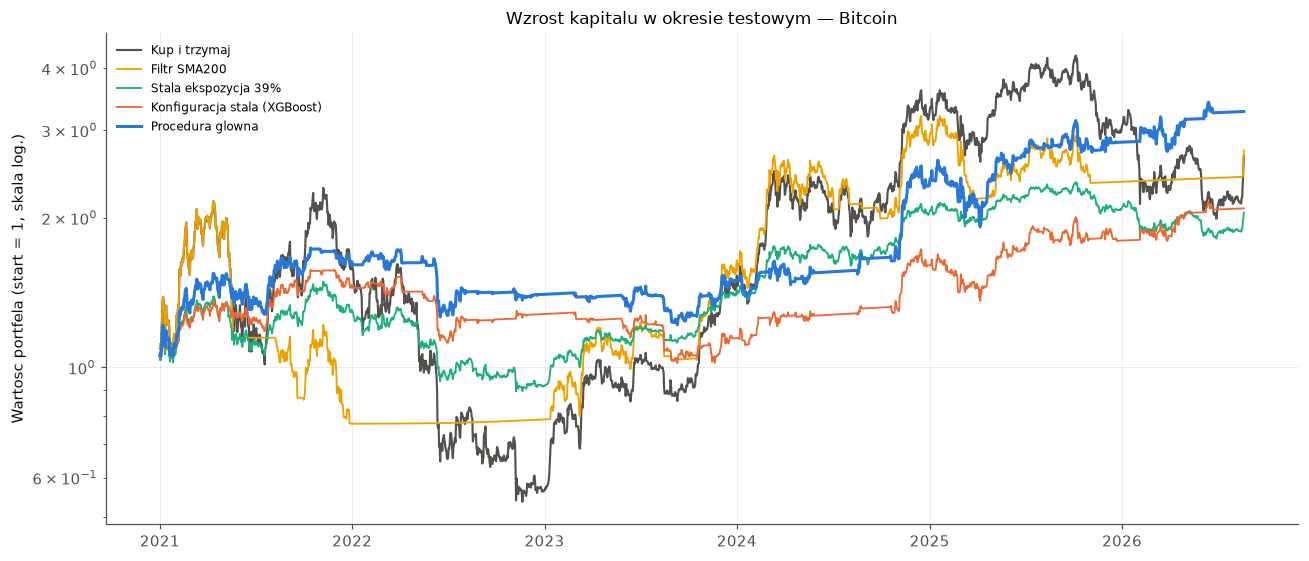

In [20]:
fig, ax = plt.subplots(figsize=(12, 5.2))
for ser, lab, kol, lw in [
        (bh_g[0], 'Kup i trzymaj', KOLORY['pasywnie'], 1.4),
        (sma_g[0], 'Filtr SMA200', KOLORY['sma'], 1.2),
        (se_g[0], f'Stala ekspozycja {ekspo_g:.0%}', KOLORY['stala_ekspozycja'], 1.2),
        (r_s, f'Konfiguracja stala ({MODEL_LABEL[GLOWNY_MODEL]})', KOLORY['stala_konfiguracja'], 1.2),
        (r_g, 'Procedura glowna', KOLORY['procedura'], 2.0)]:
    eq = (1 + ser).cumprod()
    ax.plot(eq.index, eq.values, label=lab, color=kol, linewidth=lw)
ax.set_yscale('log')
ax.set_ylabel('Wartosc portfela (start = 1, skala log.)')
ax.set_title(f'Wzrost kapitalu w okresie testowym — {TICKERS[GLOWNY_TK]}')
ax.legend(loc='upper left')
plt.tight_layout()
zapisz_rys('4_1_kapital_btc')
plt.show()

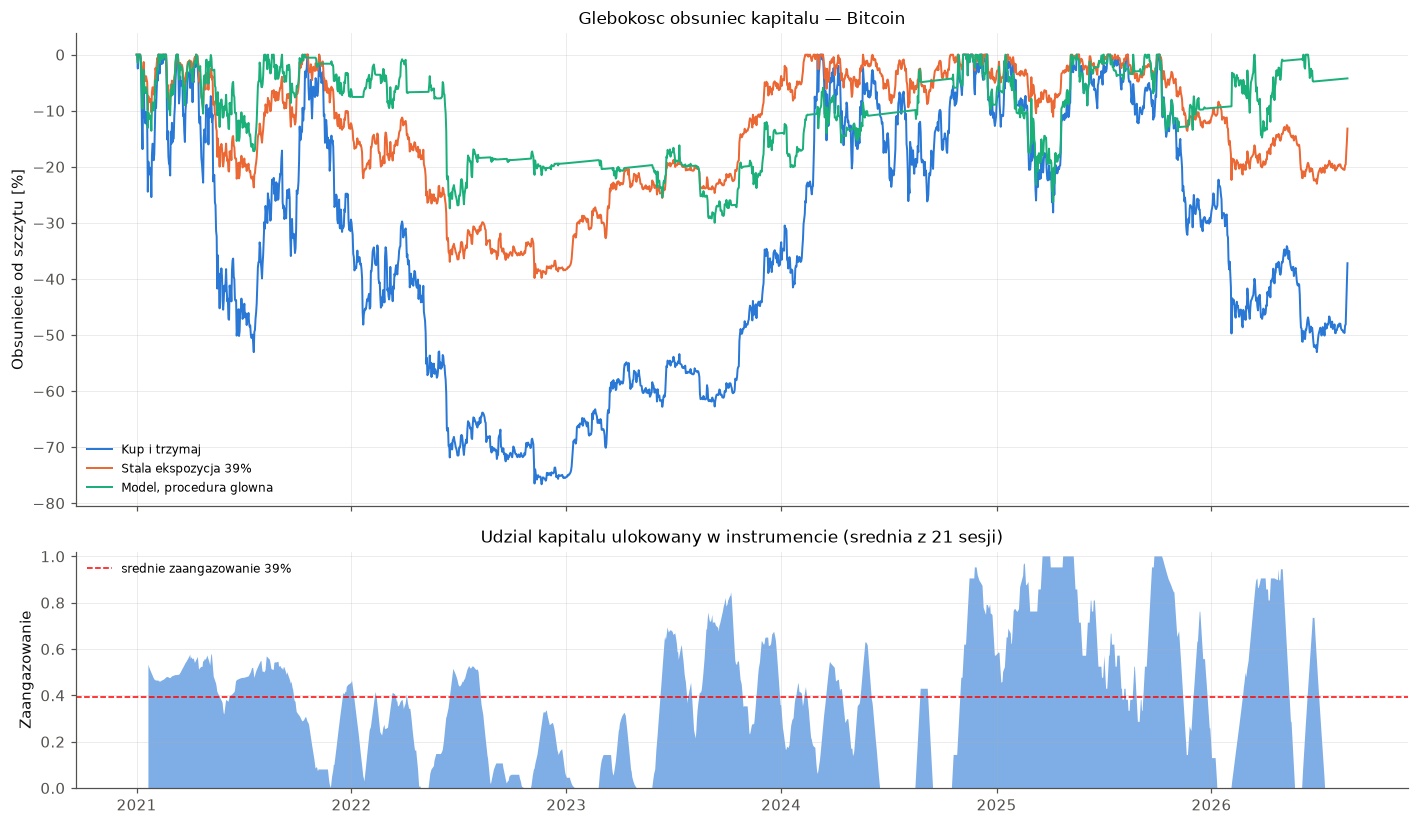

In [21]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7.6), sharex=True,
                       gridspec_kw={'height_ratios': [2, 1]})
for ser, lab in [(bh_g[0], 'Kup i trzymaj'),
                 (se_g[0], f'Stala ekspozycja {ekspo_g:.0%}'),
                 (r_g, 'Model, procedura glowna')]:
    eq = (1 + ser).cumprod()
    ax[0].plot(eq.index, (eq / eq.cummax() - 1).values * 100, label=lab, linewidth=1.3)
ax[0].set_ylabel('Obsuniecie od szczytu [%]')
ax[0].set_title(f'Glebokosc obsuniec kapitalu — {TICKERS[GLOWNY_TK]}')
ax[0].legend(fontsize=8)

ax[1].fill_between(p_g.index, p_g.rolling(21).mean().values, alpha=0.6)
ax[1].axhline(ekspo_g, color='red', linestyle='--', linewidth=1,
              label=f'srednie zaangazowanie {ekspo_g:.0%}')
ax[1].set_ylabel('Zaangazowanie')
ax[1].set_title('Udzial kapitalu ulokowany w instrumencie (srednia z 21 sesji)')
ax[1].set_ylim(0, 1.02)
ax[1].legend(fontsize=8)
plt.tight_layout()
zapisz_rys('4_2_obsuniecia_btc')
plt.show()

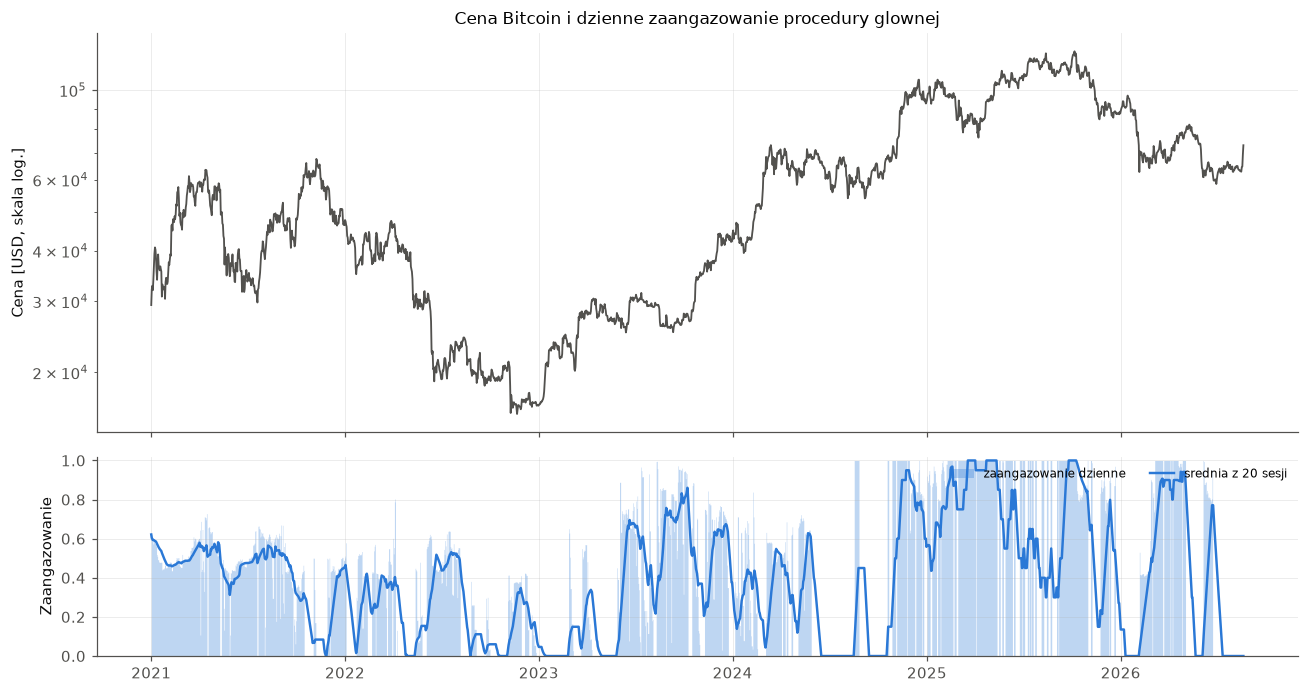

In [22]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax[0].plot(oos_g.index, oos_g['Close'].values, color=KOLORY['pasywnie'], linewidth=1.2)
ax[0].set_yscale('log')
ax[0].set_ylabel('Cena [USD, skala log.]')
ax[0].set_title(f'Cena {TICKERS[GLOWNY_TK]} i dzienne zaangazowanie procedury glownej')
ax[1].fill_between(p_g.index, p_g.values, step='post', color=KOLORY['procedura'], alpha=0.3,
                   linewidth=0, label='zaangazowanie dzienne')
ax[1].plot(p_g.index, p_g.rolling(20, min_periods=1).mean().values, color=KOLORY['procedura'],
           linewidth=1.6, label='srednia z 20 sesji')
ax[1].legend(loc='upper right', ncol=2)
ax[1].set_ylim(0, 1.02)
ax[1].set_ylabel('Zaangazowanie')
plt.tight_layout()
zapisz_rys('4_3_cena_i_zaangazowanie_btc')
plt.show()

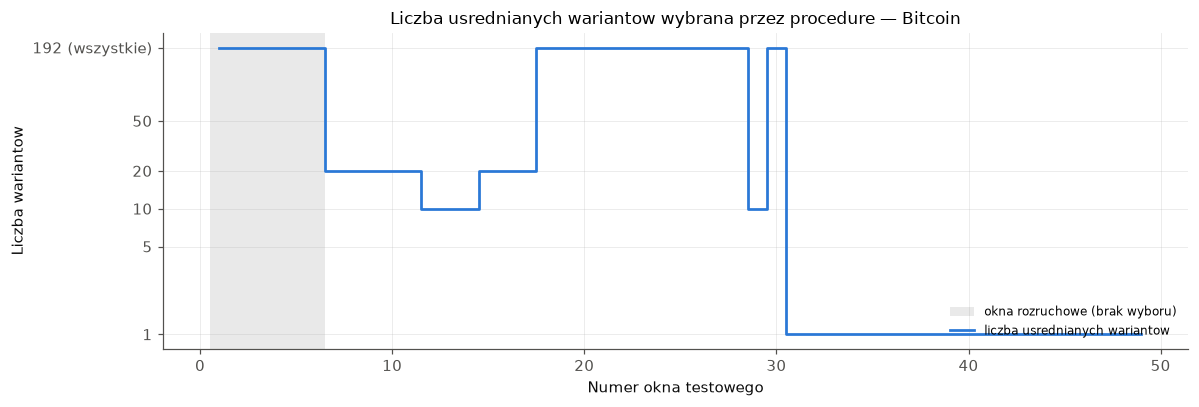

In [23]:
_nw = wynik_g['n_wybrane']
_K = wynik_g['liczba_kandydatow']
_wart = sorted(set(_K if n is None else n for n in N_KROCZACE))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axvspan(0.5, wynik_g['okna_rozruchu'] + 0.5, color=KOLORY['pasywnie'], alpha=0.12, linewidth=0,
           label='okna rozruchowe (brak wyboru)')
ax.step(np.arange(1, len(_nw) + 1), _nw.values, where='mid', color=KOLORY['procedura'], linewidth=1.8,
        label='liczba usrednianych wariantow')
ax.set_yscale('log')
ax.yaxis.set_minor_locator(NullLocator())
ax.set_yticks(_wart)
ax.set_yticklabels([f'{v} (wszystkie)' if v == _K else str(v) for v in _wart])
ax.set_xlabel('Numer okna testowego')
ax.set_ylabel('Liczba wariantow')
ax.set_title(f'Liczba usrednianych wariantow wybrana przez procedure — {TICKERS[GLOWNY_TK]}')
ax.legend(loc='lower right')
plt.tight_layout()
zapisz_rys('4_4_liczba_wariantow')
plt.show()

## 4.1. Wynik w wyodrębnionych fazach rynku

Okres testowy obejmuje pełny cykl rynku kryptowalut: hossę, głęboką bessę, odbicie, kolejną hossę
i fazę stabilizacji. Rozbicie wyniku na te fazy pokazuje, skąd pochodzi różnica względem
strategii pasywnej.

Bitcoin — wynik w wyodrebnionych fazach rynku



,Zwrot modelu,Zwrot pasywnie,Zwrot przy stalej ekspozycji,Sharpe modelu,Sharpe pasywnie,Obsuniecie modelu,Obsuniecie pasywnie,Zaangazowanie
Okres,,,,,,,,
Hossa 2021,0.6336,0.6219,0.3064,1.5248,1.0016,-0.1721,-0.5306,0.4218
Bessa 2022,-0.1411,-0.6514,-0.2975,-0.7186,-1.3687,-0.2681,-0.6674,0.2165
Odbicie 2023,0.0667,1.6567,0.5489,0.1692,2.3268,-0.1647,-0.2006,0.3524
Hossa 2024,0.5487,1.1378,0.4370,1.5115,1.5915,-0.1040,-0.2618,0.3173
2025-2026,0.4119,-0.1704,0.0032,0.6997,-0.1258,-0.2625,-0.5306,0.5553


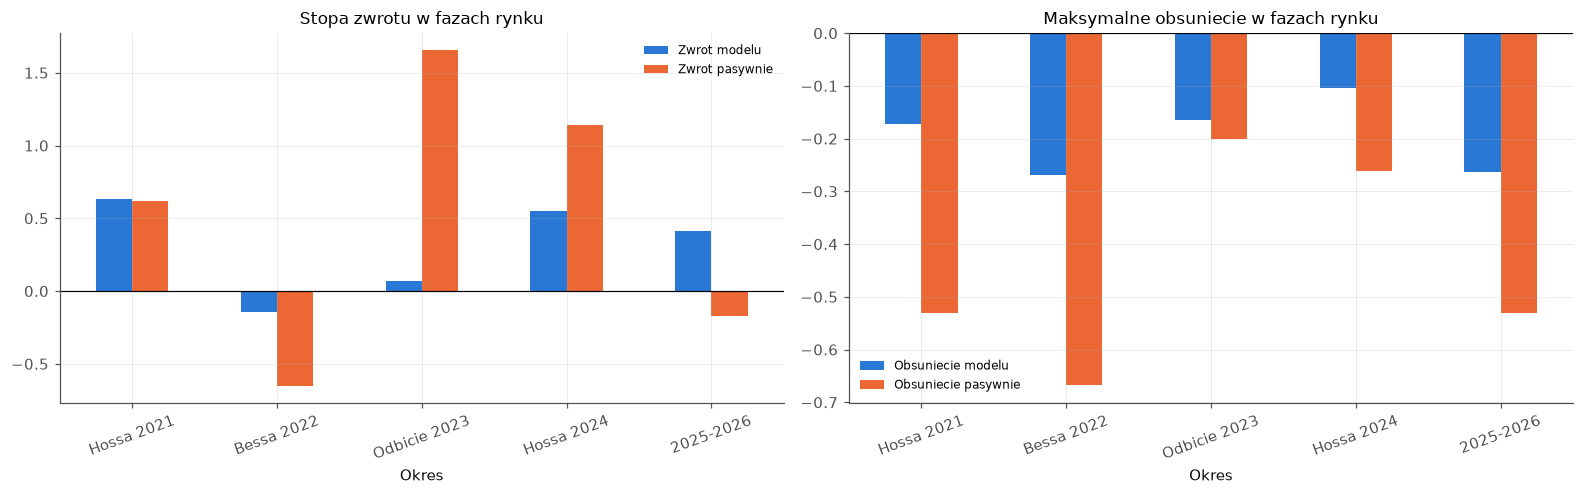

In [24]:
rows = []
for nazwa, (s, e) in OKRESY.items():
    s = pd.Timestamp(s)
    e = pd.Timestamp(e) if e else r_g.index.max()
    mask = (r_g.index >= s) & (r_g.index <= e)
    if mask.sum() < 20:
        continue
    a = compute_metrics(r_g[mask], p_g[mask], t_g[mask], ticker=GLOWNY_TK,
                        asset_returns=oos_g['next_return'][mask], label='')
    b = compute_metrics(bh_g[0][mask], bh_g[1][mask], bh_g[2][mask], ticker=GLOWNY_TK, label='')
    c = compute_metrics(se_g[0][mask], se_g[1][mask], se_g[2][mask], ticker=GLOWNY_TK, label='')
    rows.append({'Okres': nazwa, 'Zwrot modelu': a['Zwrot'], 'Zwrot pasywnie': b['Zwrot'],
                 'Zwrot przy stalej ekspozycji': c['Zwrot'],
                 'Sharpe modelu': a['Sharpe'], 'Sharpe pasywnie': b['Sharpe'],
                 'Obsuniecie modelu': a['Max obsuniecie'],
                 'Obsuniecie pasywnie': b['Max obsuniecie'],
                 'Zaangazowanie': a['Zaangazowanie']})
podokresy = pd.DataFrame(rows).set_index('Okres')
print(f'{TICKERS[GLOWNY_TK]} — wynik w wyodrebnionych fazach rynku\n')
display(podokresy.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))
podokresy[['Zwrot modelu', 'Zwrot pasywnie']].plot(kind='bar', ax=axes[0])
axes[0].set_title('Stopa zwrotu w fazach rynku')
axes[0].axhline(0, color='black', linewidth=0.8)
podokresy[['Obsuniecie modelu', 'Obsuniecie pasywnie']].plot(kind='bar', ax=axes[1])
axes[1].set_title('Maksymalne obsuniecie w fazach rynku')
axes[1].axhline(0, color='black', linewidth=0.8)
for a in axes:
    a.tick_params(axis='x', rotation=20)
plt.tight_layout()
zapisz_rys('4_5_fazy_rynku')
plt.show()

## 4.2. Wszystkie rynki

Procedura główna i to samo zadanie prognostyczne zastosowane do trzech rynków. Zestawienie pozwala
ocenić, czy oddziaływanie na profil ryzyka jest cechą ogólną, czy właściwością jednego rynku.

In [25]:
rows = []
for tk in TICKERS:
    if (tk, GLOWNE_ZADANIE) not in wf_results:
        continue
    oos = wf_results[(tk, GLOWNE_ZADANIE)]['oos']
    bh = buy_and_hold(oos, tk)
    m_bh = compute_metrics(bh[0], bh[1], bh[2], ticker=tk, label='')
    wyn = procedura_glowna(oos, tk)
    r, p_, t_ = backtest(wyn['pos'], oos, tk)
    met = compute_metrics(r, p_, t_, ticker=tk, asset_returns=oos['next_return'], label='')
    rows.append({
        'Instrument': TICKERS[tk],
        'Obsuniecie procedury': met['Max obsuniecie'],
        'Obsuniecie pasywnie': m_bh['Max obsuniecie'],
        'Calmar procedury': met['Calmar'], 'Calmar pasywnie': m_bh['Calmar'],
        'Sortino procedury': met['Sortino'], 'Sortino pasywnie': m_bh['Sortino'],
        'Sharpe procedury': met['Sharpe'], 'Sharpe pasywnie': m_bh['Sharpe'],
        'Zaangazowanie': met['Zaangazowanie']})
rynki = pd.DataFrame(rows)
print(f'Zadanie: {NAZWA_ZADANIA[GLOWNE_ZADANIE]}, procedura glowna\n')
display(rynki.round(4).reset_index(drop=True))

Zadanie: ryzyko duzego spadku, procedura glowna



,Instrument,Obsuniecie procedury,Obsuniecie pasywnie,Calmar procedury,Calmar pasywnie,Sortino procedury,Sortino pasywnie,Sharpe procedury,Sharpe pasywnie,Zaangazowanie
0,Bitcoin,-0.2998,-0.7663,0.7805,0.2477,1.1910,0.7846,0.7664,0.5327,0.3932
1,S&P 500 (akcje),-0.2185,-0.2450,0.2715,0.6205,0.3824,1.0633,0.2689,0.7357,0.5328
2,Obligacje skarbowe USA 20+ lat,-0.3425,-0.4370,-0.1717,-0.1863,-1.1415,-0.9415,-0.8630,-0.6850,0.5171


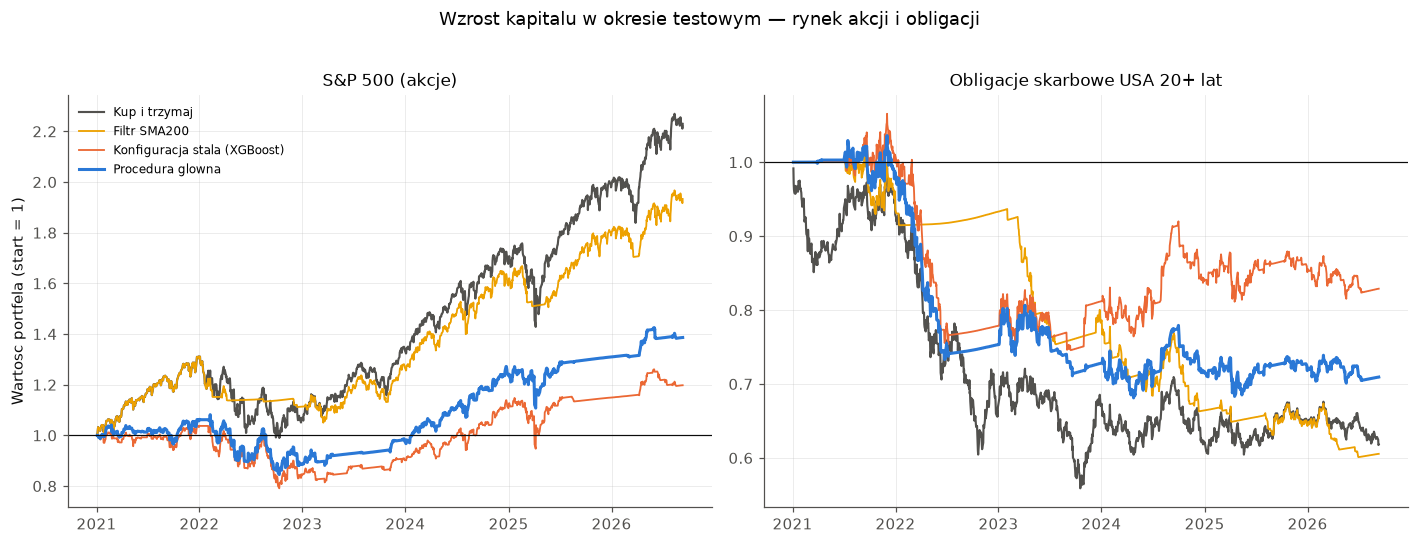

In [26]:
_inne = [t for t in TICKERS if t != GLOWNY_TK and (t, GLOWNE_ZADANIE) in wf_results]
fig, axes = plt.subplots(1, len(_inne), figsize=(13, 4.8), squeeze=False)
for ax, tk in zip(axes[0], _inne):
    oos = wf_results[(tk, GLOWNE_ZADANIE)]['oos']
    for ser, lab, kol, lw in [
            (buy_and_hold(oos, tk)[0], 'Kup i trzymaj', KOLORY['pasywnie'], 1.4),
            (sma_benchmark(oos, tk, 200)[0], 'Filtr SMA200', KOLORY['sma'], 1.2),
            (backtest(build_positions(oos, tk, f'proba_{GLOWNY_MODEL}', KONFIGURACJA_STALA), oos, tk)[0],
             f'Konfiguracja stala ({MODEL_LABEL[GLOWNY_MODEL]})', KOLORY['stala_konfiguracja'], 1.2),
            (backtest(procedura_glowna(oos, tk)['pos'], oos, tk)[0], 'Procedura glowna',
             KOLORY['procedura'], 2.0)]:
        eq = (1 + ser).cumprod()
        ax.plot(eq.index, eq.values, label=lab, color=kol, linewidth=lw)
    ax.axhline(1, color=KOLORY['tekst'], linewidth=0.8)
    ax.set_title(TICKERS[tk])
axes[0][0].set_ylabel('Wartosc portfela (start = 1)')
axes[0][0].legend(loc='upper left')
plt.suptitle('Wzrost kapitalu w okresie testowym — rynek akcji i obligacji', y=1.02)
plt.tight_layout()
zapisz_rys('4_6_kapital_spy_tlt')
plt.show()

## 4.3. Istotność statystyczna przewagi

Test Jobsona-Korkiego z korektą Memmela weryfikuje hipotezę o równości wskaźników Sharpe'a
strategii aktywnej i pasywnej. Bootstrap stacjonarny Politisa-Romano wyznacza przedziały ufności
wskaźnika, zachowując strukturę autokorelacji szeregu. Deflated Sharpe Ratio koryguje wynik
na liczbę przebadanych konfiguracji i podaje próg, który wskaźnik musiałby przekroczyć, aby nie
dawał się wyjaśnić samą liczbą prób.

Korekta obejmuje wszystkie konfiguracje przebadane w toku badania: kombinacje instrumentu,
zadania, modelu i reguły inwestycyjnej oraz 576 wariantów reguły dla trzech modeli, z których
korzystały porównywane warianty procedury głównej (sekcja 5.6). Uwzględnienie całego tego zbioru
jest uzasadnione, ponieważ wariant główny wybrano po porównaniu wyników. Test i przedziały ufności podano zarówno
dla procedury głównej, jak i dla konfiguracji stałej.

In [27]:
WARIANTY_KALIBRACJI = {
    'regula prosta': STRATEGIA_PROSTA,
    'prog 0,55': dict(mode='binary', threshold=0.55),
    'skalowanie pozycji': dict(mode='scaled', threshold=0.50, k=4.0),
    'kontrola zmiennosci': dict(mode='binary', threshold=0.50, vol_target=0.30),
    'filtr SMA200': dict(mode='binary', threshold=0.50, sma_filter=200),
    'konfiguracja stala': KONFIGURACJA_STALA,
}

sh_all = []
for (tk, mode), res in wf_results.items():
    if tk == TICKER_WERYFIKACYJNY:
        continue
    oos = res['oos']
    for m in MODELS:
        for cfg in WARIANTY_KALIBRACJI.values():
            r, _, _ = backtest(build_positions(oos, tk, f'proba_{m}', cfg), oos, tk)
            s = sharpe_ann(r, tk)
            if np.isfinite(s):
                sh_all.append(s / np.sqrt(FREQ_MAP[tk]))
N_PROB = len(sh_all) + len(MODELE_PROCEDURY) * len(siatka_konfiguracji())
WARIANCJA_PROB = float(np.var(sh_all)) if len(sh_all) > 2 else 0.01
print(f'Liczba konfiguracji uwzglednionych w korekcie na wielokrotne proby: {N_PROB}')

rows = []
for tk in TICKERS:
    if (tk, GLOWNE_ZADANIE) not in wf_results:
        continue
    oos = wf_results[(tk, GLOWNE_ZADANIE)]['oos']
    rf = rf_daily_for(oos.index, FREQ_MAP[tk])
    bh = buy_and_hold(oos, tk)[0]
    for etykieta, pos in [
            ('procedura glowna', procedura_glowna(oos, tk)['pos']),
            (f'konfiguracja stala ({MODEL_LABEL[GLOWNY_MODEL]})',
             build_positions(oos, tk, f'proba_{GLOWNY_MODEL}', KONFIGURACJA_STALA))]:
        r, _, _ = backtest(pos, oos, tk)
        jk = sharpe_jk_memmel(r, bh, rf=rf)
        dsr = deflated_sharpe_ratio(r, N_PROB, FREQ_MAP[tk], WARIANCJA_PROB, rf=rf)
        rows.append({'Instrument': TICKERS[tk], 'Strategia': etykieta,
                     'Sharpe modelu': sharpe_ann(r, tk), 'Sharpe pasywnie': sharpe_ann(bh, tk),
                     'Statystyka z': jk['z'], 'p-value': jk['p_value'],
                     'Istotne (5%)': 'tak' if (np.isfinite(jk['p_value'])
                                               and jk['p_value'] < 0.05) else 'nie',
                     'Deflated Sharpe': dsr['DSR'], 'Prog SR0': dsr['SR0']})
testy_sharpe = pd.DataFrame(rows)
print(f"\nTest roznicy wskaznika Sharpe'a wzgledem strategii pasywnej "
      f"({NAZWA_ZADANIA[GLOWNE_ZADANIE]})\n")
display(testy_sharpe.round(4).reset_index(drop=True))

Liczba konfiguracji uwzglednionych w korekcie na wielokrotne proby: 792

Test roznicy wskaznika Sharpe'a wzgledem strategii pasywnej (ryzyko duzego spadku)



,Instrument,Strategia,Sharpe modelu,Sharpe pasywnie,Statystyka z,p-value,Istotne (5%),Deflated Sharpe,Prog SR0
0,Bitcoin,procedura glowna,0.7664,0.5327,0.7874,0.4310,nie,0.0007,2.0902
1,Bitcoin,konfiguracja stala (XGBoost),0.5578,0.5327,0.0785,0.9375,nie,0.0001,2.0902
2,S&P 500 (akcje),procedura glowna,0.2689,0.7357,-1.7297,0.0837,nie,0.0002,1.7368
3,S&P 500 (akcje),konfiguracja stala (XGBoost),0.0599,0.7357,-2.6017,0.0093,tak,0.0000,1.7368
4,Obligacje skarbowe USA 20+ lat,procedura glowna,-0.8630,-0.6850,-0.5589,0.5762,nie,0.0000,1.7368
5,Obligacje skarbowe USA 20+ lat,konfiguracja stala (XGBoost),-0.5460,-0.6850,0.4329,0.6651,nie,0.0000,1.7368


In [28]:
rows = []
for nazwa, ser in [('Kup i trzymaj', bh_g[0]), (f'Stala ekspozycja {ekspo_g:.0%}', se_g[0]),
                   ('Filtr SMA200', sma_g[0]),
                   (f'Model, konfiguracja stala ({MODEL_LABEL[GLOWNY_MODEL]})', r_s),
                   ('Model, procedura glowna', r_g)]:
    ci = bootstrap_ci(ser, freq_g, rf=rf_g)
    if ci:
        rows.append({'Strategia': nazwa, **ci})
bootstrap = pd.DataFrame(rows)
print(f"Przedzialy ufnosci wskaznika Sharpe'a — {TICKERS[GLOWNY_TK]} "
      f"(bootstrap stacjonarny, 95%)\n")
display(bootstrap.round(4).reset_index(drop=True))

Przedzialy ufnosci wskaznika Sharpe'a — Bitcoin (bootstrap stacjonarny, 95%)



,Strategia,Sharpe,Dolna granica,Gorna granica,P(Sharpe>0)
0,Kup i trzymaj,0.5327,-0.3175,1.3460,0.8810
1,Stala ekspozycja 39%,0.5327,-0.3175,1.3460,0.8810
2,Filtr SMA200,0.5582,-0.3883,1.4239,0.8750
3,"Model, konfiguracja stala (XGBoost)",0.5578,-0.1831,1.3387,0.9270
4,"Model, procedura glowna",0.7664,0.0810,1.4777,0.9830


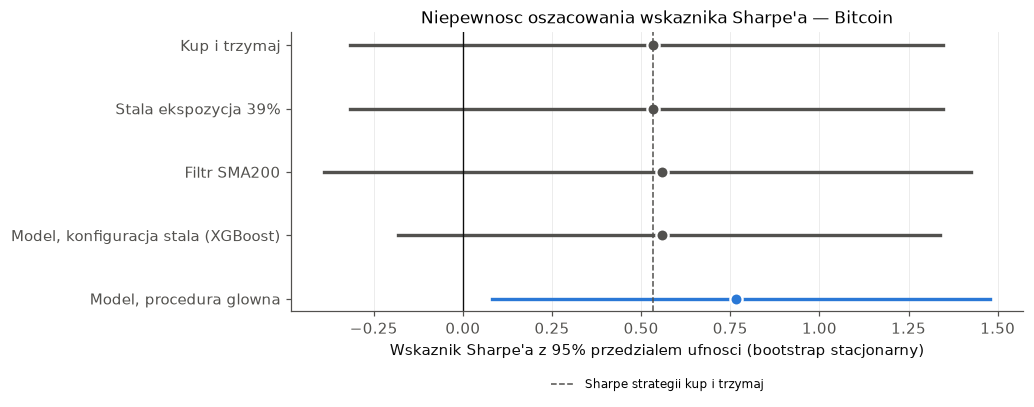

In [29]:
_b = bootstrap.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 3.9))
for i, row in _b.iterrows():
    kol = KOLORY['procedura'] if 'procedura' in row['Strategia'] else KOLORY['pasywnie']
    ax.plot([row['Dolna granica'], row['Gorna granica']], [i, i], color=kol, linewidth=2.2)
    ax.plot(row['Sharpe'], i, 'o', color=kol, markersize=8, markeredgecolor='white',
            markeredgewidth=1.5)
ax.axvline(0, color=KOLORY['tekst'], linewidth=0.9)
ax.axvline(sharpe_ann(bh_g[0], GLOWNY_TK), color=KOLORY['pasywnie'], linestyle='--', linewidth=1,
           label='Sharpe strategii kup i trzymaj')
ax.set_yticks(range(len(_b)))
ax.set_yticklabels(_b['Strategia'])
ax.grid(axis='y', visible=False)
ax.set_xlabel("Wskaznik Sharpe'a z 95% przedzialem ufnosci (bootstrap stacjonarny)")
ax.set_title(f"Niepewnosc oszacowania wskaznika Sharpe'a — {TICKERS[GLOWNY_TK]}")
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
zapisz_rys('4_7_przedzialy_ufnosci')
plt.show()

**Interpretacja.**

Hipoteza potwierdza się w części dotyczącej profilu ryzyka. Na bitcoinie procedura główna uzyskuje
przy tym również wyższą stopę zwrotu i wyższy wskaźnik Sharpe'a niż strategia pasywna, lecz różnica
wskaźnika Sharpe'a nie jest istotna statystycznie, a na pozostałych rynkach przewaga nie występuje.

Oddziaływanie na profil ryzyka jest na bitcoinie wyraźne. Maksymalne obsunięcie kapitału jest
ponad dwukrotnie płytsze niż przy pełnej ekspozycji, a zmienność roczna mniej więcej o połowę
niższa, ponieważ przez znaczną część okresu pozycja pozostaje zamknięta lub ograniczona przez
kontrolę zmienności.

Nie jest to jednak cecha niezależna od rynku. Na obligacjach obsunięcie również maleje, natomiast
na rynku akcji, gdzie obsunięcie strategii pasywnej jest umiarkowane, zmniejsza się nieznacznie
kosztem wyraźnie niższej stopy zwrotu. Redukcja ryzyka pojawia się zatem tam, gdzie ryzyko pasywnej ekspozycji jest
głębokie, i zanika tam, gdzie pozostaje umiarkowane — jest funkcją skali ryzyka obecnego na rynku,
nie właściwością samego podejścia.

Wskaźniki Calmar i Sortino, uwzględniające odpowiednio głębokość obsunięć i wyłącznie odchylenia
niekorzystne, są dla procedury głównej wyraźnie korzystniejsze niż dla strategii pasywnej i dla
filtru trendu. Najsilniej, ponad trzykrotnie, poprawia się wskaźnik Calmar, co odpowiada
charakterowi zmiany: strategia przede wszystkim ogranicza najgłębsze obsunięcia.

Rozbicie na fazy rynku pokazuje mechanizm. Procedura ogranicza straty w fazie spadkowej
i przewyższa strategię pasywną w fazie stabilizacji. W hossie 2021 dorównuje strategii pasywnej przy
ponad trzykrotnie płytszym obsunięciu, natomiast w odbiciu 2023 i w hossie 2024 pozostaje wyraźnie
w tyle. Względem strategii o stałej ekspozycji procedura wypada lepiej w czterech z pięciu faz,
a jedynym wyjątkiem jest odbicie 2023. Nabywa zatem ochronę przed spadkami w zamian za udział
w części wzrostów, a bilans tej wymiany zależy od struktury faz rynkowych
w badanym okresie.

Porównanie ze strategią o stałej, obniżonej ekspozycji jest w tej sekcji rozstrzygające, ponieważ
oddziela efekt wyboru momentów od efektu samego zmniejszenia pozycji. Procedura główna
przewyższa ją na stopie zwrotu i na wskaźnikach skorygowanych o ryzyko przy płytszym obsunięciu,
a zatem wybór momentów wnosi wartość dodaną ponad samo ograniczenie zaangażowania. Część efektu
pozostaje jednak osiągalna bez żadnego modelu i praktycznie bez transakcji. Procedura wypada też
wyraźnie korzystniej niż konfiguracja stała, co jest zgodne z wynikiem sekcji 5.2: parametry
ustalone z góry na krótszej próbie nie zachowują trafności, a ich wyznaczanie na bieżąco tę
słabość ogranicza.

Testy istotności ograniczają siłę tych wniosków. Test różnicy wskaźnika Sharpe'a nie potwierdza
przewagi procedury głównej nad strategią pasywną na żadnym z rynków. Przedziały
ufności wyznaczone bootstrapem stacjonarnym są szerokie, a dla bitcoina obejmują wartości ujemne
nawet w przypadku strategii pasywnej, co oznacza, że przy zmienności rzędu 57% w skali roku
niespełna sześcioletnia próba nie pozwala rozstrzygnąć nawet tego, czy samo utrzymywanie pozycji
miało dodatnią oczekiwaną stopę zwrotu skorygowaną o ryzyko. Procedura główna jest jedyną strategią
na bitcoinie, dla której dolna granica przedziału ufności wskaźnika Sharpe'a jest dodatnia. Deflated Sharpe Ratio przyjmuje
wartości bliskie zeru przy progu wyraźnie przekraczającym obserwowane wartości wskaźnika.

Zestawienie tego z sekcją 3 nie stanowi sprzeczności. Test Pesarana-Timmermanna weryfikuje
zgodność prognozy z realizacją na ponad dwóch tysiącach obserwacji i wykazuje istotność. Test
różnicy wskaźnika Sharpe'a weryfikuje wielkość ekonomiczną obciążoną zmiennością instrumentu
i jej nie wykazuje. Zdolność prognostyczna jest zatem realna, lecz zbyt mała, aby przy dostępnej
długości próby przełożyć się na weryfikowalną przewagę w stopie zwrotu.

---

# 5. Hipoteza 3: wpływ decyzji metodologicznych

Dotychczasowe sekcje traktowały procedurę badawczą jako ustaloną i pytały, co z niej wynika dla
rynku. Ta sekcja odwraca pytanie: przy niezmienionych danych bada, jak silnie wynik zależy od
decyzji podjętych w trakcie konstruowania badania.

Zbadano pięć takich decyzji: specyfikację zbioru zmiennych objaśniających, wartości parametrów
reguły inwestycyjnej, inicjalizację modelu, przyjęty poziom kosztów transakcyjnych oraz skład
zbioru kandydatów procedury głównej.

## 5.1. Specyfikacja zbioru zmiennych objaśniających

Pierwotna wersja zbioru zawierała zmienne makroekonomiczne w postaciach poziomowych: spread
kredytowy oraz nachylenie krzywej rentowności. Test ADF odrzucił ich stacjonarność, przy czym
najgorszy wynik dotyczył zmiennej odwzorowującej spread kredytowy, dla której wartość p wyniosła
0,935, co odpowiada szeregowi praktycznie nieodróżnialnemu od błądzenia losowego. Po zastąpieniu
tych zmiennych pierwszymi różnicami, przy niezmienionym okresie testowym i niezmienionej
procedurze, wskaźnik Sharpe'a najlepszej konfiguracji spadł o wartość wielokrotnie
przewyższającą przewagę tej konfiguracji nad strategią pasywną.

Pierwotny wynik był zatem w znacznej części zależnością pozorną w rozumieniu Grangera i Newbolda
(1974): regresja dwóch szeregów z pierwiastkiem jednostkowym wykazuje zależność statystyczną
nawet przy braku związku przyczynowego, a standardowe miary dopasowania nie sygnalizują problemu.

*Poniższe zestawienie pochodzi z osobnego przebiegu pętli uczącej, ponieważ wymaga innego zbioru
zmiennych objaśniających niż wersja finalna. Wszystkie pozostałe elementy procedury, w tym
podział na okna i okres testowy, były identyczne.*

In [30]:
KOL_SH = 'Sharpe najlepszej konfiguracji (osobny przebieg)'
specyfikacja = pd.DataFrame([
    {'Specyfikacja zbioru zmiennych': 'zmienne makro w poziomach (wersja pierwotna)',
     KOL_SH: 0.945, 'Najwyzsza wartosc p testu ADF': 0.935, 'Zmienne niestacjonarne': 4},
    {'Specyfikacja zbioru zmiennych': 'zmienne makro w pierwszych roznicach (wersja finalna)',
     KOL_SH: 0.564, 'Najwyzsza wartosc p testu ADF': 0.137, 'Zmienne niestacjonarne': 2},
]).set_index('Specyfikacja zbioru zmiennych')

print('Wplyw specyfikacji zbioru zmiennych na wynik, przy niezmienionym okresie testowym\n')
display(specyfikacja)

_sh_bh_ref = sharpe_ann(bh_g[0], GLOWNY_TK)
_spadek = specyfikacja[KOL_SH].iloc[0] - specyfikacja[KOL_SH].iloc[1]
print(f"\nSpadek wskaznika Sharpe po zastapieniu zmiennych ich roznicami : {_spadek:.3f}")
print(f"Strategia pasywna w tym samym okresie testowym                  : {_sh_bh_ref:.3f}")
print(f"Przewaga wersji finalnej nad strategia pasywna                   : "
      f"{specyfikacja[KOL_SH].iloc[1] - _sh_bh_ref:.3f}")
print('\nSpadek wywolany sama zmiana specyfikacji zbioru zmiennych jest zatem '
      'wielokrotnie wiekszy\nniz przewaga tej konfiguracji nad strategia pasywna.')

Wplyw specyfikacji zbioru zmiennych na wynik, przy niezmienionym okresie testowym



,Sharpe najlepszej konfiguracji (osobny przebieg),Najwyzsza wartosc p testu ADF,Zmienne niestacjonarne
Specyfikacja zbioru zmiennych,,,
zmienne makro w poziomach (wersja pierwotna),0.9450,0.9350,4
zmienne makro w pierwszych roznicach (wersja finalna),0.5640,0.1370,2



Spadek wskaznika Sharpe po zastapieniu zmiennych ich roznicami : 0.381
Strategia pasywna w tym samym okresie testowym                  : 0.533
Przewaga wersji finalnej nad strategia pasywna                   : 0.031

Spadek wywolany sama zmiana specyfikacji zbioru zmiennych jest zatem wielokrotnie wiekszy
niz przewaga tej konfiguracji nad strategia pasywna.


## 5.2. Wartości parametrów reguły inwestycyjnej

Parametry konfiguracji stałej — progi 0,55 i 0,45, pięć sesji minimalnego utrzymania pozycji,
docelowa zmienność 30% — zostały ustalone na wcześniejszym etapie badania, na krótszej próbie,
i nie były korygowane po uzyskaniu ostatecznych wyników. Poniżej przebadano 192 kombinacje tych
parametrów dla modelu XGBoost, aby ocenić, gdzie w rozkładzie wyników znajduje się ta konkretna
konfiguracja.

Dla porównania zaznaczono wynik procedury głównej. Porównanie to nie jest symetryczne: każda
kombinacja siatki oceniana jest na całym okresie testowym, czyli z wiedzą niedostępną w chwili
podejmowania decyzji, podczas gdy procedura główna korzysta wyłącznie z okien wcześniejszych.

Przebadano 192 kombinacji parametrow reguly inwestycyjnej.

Mediana Sharpe                 : 0.5989
Kwartyle                       : [0.5169, 0.6974]
Zakres                         : [0.2366, 0.9686]
Kup i trzymaj                  : 0.5327
Filtr SMA200                   : 0.5581
Konfiguracja stala             : 0.5578 (percentyl 36)
Procedura glowna               : 0.7664 (percentyl 87)
Udzial kombinacji > pasywna    : 70.8%
Udzial kombinacji > SMA200     : 63.5%


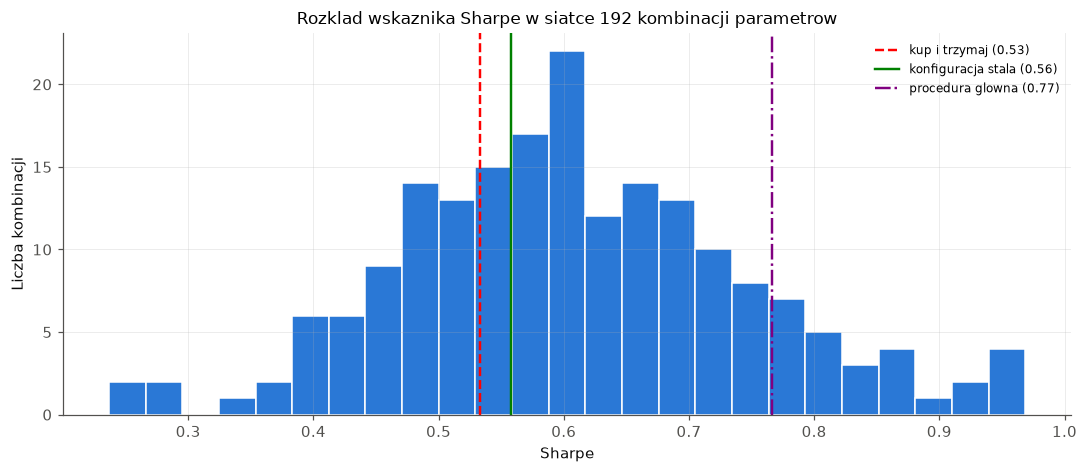

In [31]:
SIATKA = dict(entry=[0.52, 0.55, 0.58, 0.60], szerokosc=[0.05, 0.10, 0.15],
              min_hold=[0, 3, 5, 8], vol_target=[None, 0.20, 0.30, 0.40])

sh_bh = sharpe_ann(bh_g[0], GLOWNY_TK)
sh_sma = sharpe_ann(sma_g[0], GLOWNY_TK)
sh_stala = sharpe_ann(r_s, GLOWNY_TK)
sh_procedura = sharpe_ann(r_g, GLOWNY_TK)

rows = []
for e in SIATKA['entry']:
    for w in SIATKA['szerokosc']:
        for mh in SIATKA['min_hold']:
            for vt in SIATKA['vol_target']:
                cfg = dict(mode='binary', threshold=e, exit_threshold=round(e - w, 3),
                           min_hold=mh)
                if vt is not None:
                    cfg['vol_target'] = vt
                pos = build_positions(oos_g, GLOWNY_TK, f'proba_{GLOWNY_MODEL}', cfg)
                r, _, t_ = backtest(pos, oos_g, GLOWNY_TK)
                eq = (1 + r).cumprod()
                rows.append({'Prog wejscia': e, 'Szerokosc strefy': w, 'Min. sesji': mh,
                             'Docelowa zmiennosc': vt if vt is not None else np.nan,
                             'Sharpe': sharpe_ann(r, GLOWNY_TK),
                             'Zwrot': (1 + r).prod() - 1,
                             'Max obsuniecie': (eq / eq.cummax() - 1).min(),
                             'Rotacja': t_.sum() / (len(r) / freq_g),
                             'Zaangazowanie': pos.mean()})
siatka = pd.DataFrame(rows)

print(f'Przebadano {len(siatka)} kombinacji parametrow reguly inwestycyjnej.\n')
print(f"Mediana Sharpe                 : {siatka['Sharpe'].median():.4f}")
print(f"Kwartyle                       : [{siatka['Sharpe'].quantile(0.25):.4f}, "
      f"{siatka['Sharpe'].quantile(0.75):.4f}]")
print(f"Zakres                         : [{siatka['Sharpe'].min():.4f}, "
      f"{siatka['Sharpe'].max():.4f}]")
print(f"Kup i trzymaj                  : {sh_bh:.4f}")
print(f"Filtr SMA200                   : {sh_sma:.4f}")
print(f"Konfiguracja stala             : {sh_stala:.4f} "
      f"(percentyl {(siatka['Sharpe'] < sh_stala).mean()*100:.0f})")
print(f"Procedura glowna               : {sh_procedura:.4f} "
      f"(percentyl {(siatka['Sharpe'] < sh_procedura).mean()*100:.0f})")
print(f"Udzial kombinacji > pasywna    : {(siatka['Sharpe'] > sh_bh).mean():.1%}")
print(f"Udzial kombinacji > SMA200     : {(siatka['Sharpe'] > sh_sma).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.hist(siatka['Sharpe'], bins=25, edgecolor='white')
ax.axvline(sh_bh, color='red', linestyle='--', label=f'kup i trzymaj ({sh_bh:.2f})')
ax.axvline(sh_stala, color='green', label=f'konfiguracja stala ({sh_stala:.2f})')
ax.axvline(sh_procedura, color='purple', linestyle='-.',
           label=f'procedura glowna ({sh_procedura:.2f})')
ax.set_title('Rozklad wskaznika Sharpe w siatce 192 kombinacji parametrow')
ax.set_xlabel('Sharpe')
ax.set_ylabel('Liczba kombinacji')
ax.legend(fontsize=8)
plt.tight_layout()
zapisz_rys('5_1_siatka_parametrow')
plt.show()

## 5.3. Inicjalizacja modelu i schemat treningu

Cztery scenariusze przy niezmienionej regule inwestycyjnej: dwie odmienne inicjalizacje generatora
liczb pseudolosowych, skrócenie okna treningowego do 750 obserwacji, czyli około dwóch lat, oraz przesunięcie początku okresu
testowego o rok. Wariant podstawowy odpowiada procedurze głównej omawianej w sekcji 4. W każdym
scenariuszu procedura stosowana jest w całości, łącznie z bieżącym wyborem parametrów
reguły; test Pesarana-Timmermanna dotyczy prognoz modelu XGBoost.

In [32]:
OPIS_SCEN = {
    'W0. wariant podstawowy': 'ustawienia z czesci glownej',
    'W1. ziarno 7': 'inna inicjalizacja generatora',
    'W2. ziarno 123': 'inna inicjalizacja generatora',
    'W3. okno kroczace 750': 'okno treningowe skrocone do 750 obserwacji (ok. 2 lata)',
    'W4. OOS od 2022': 'okres testowy przesuniety o rok',
}


def ocena_scenariusza(nazwa, oos_df):
    pos = procedura_glowna(oos_df, GLOWNY_TK)['pos']
    r, p_, t_ = backtest(pos, oos_df, GLOWNY_TK, cost=TRANSACTION_COST)
    a = compute_metrics(r, p_, t_, ticker=GLOWNY_TK,
                        asset_returns=oos_df['next_return'], label='')
    bh = buy_and_hold(oos_df, GLOWNY_TK)
    b = compute_metrics(bh[0], bh[1], bh[2], ticker=GLOWNY_TK, label='')
    pt = pesaran_timmermann(oos_df['y_true'].values,
                            (oos_df[f'proba_{GLOWNY_MODEL}'].values > 0.5).astype(int))
    return {'Scenariusz': nazwa, 'Opis': OPIS_SCEN.get(nazwa, ''),
            'Sharpe modelu': a['Sharpe'], 'Sharpe pasywnie': b['Sharpe'],
            'Zwrot modelu': a['Zwrot'], 'Zwrot pasywnie': b['Zwrot'],
            'Obsuniecie modelu': a['Max obsuniecie'],
            'Obsuniecie pasywnie': b['Max obsuniecie'],
            f'Test PT, {MODEL_LABEL[GLOWNY_MODEL]} (p)': pt['p_value']}


rows = [ocena_scenariusza('W0. wariant podstawowy', oos_g)]
rows += [ocena_scenariusza(n, robust[n]['oos']) for n in OPIS_SCEN if n in robust]
odpornosc = pd.DataFrame(rows).set_index('Scenariusz')
print(f'{TICKERS[GLOWNY_TK]} — wynik przy zmienionych zalozeniach '
      '(procedura glowna)\n')
display(odpornosc.round(4))

Bitcoin — wynik przy zmienionych zalozeniach (procedura glowna)



,Opis,Sharpe modelu,Sharpe pasywnie,Zwrot modelu,Zwrot pasywnie,Obsuniecie modelu,Obsuniecie pasywnie,"Test PT, XGBoost (p)"
Scenariusz,,,,,,,,
W0. wariant podstawowy,ustawienia z czesci glownej,0.7664,0.5327,2.2728,1.6644,-0.2998,-0.7663,0.0003
W1. ziarno 7,inna inicjalizacja generatora,0.5524,0.5327,1.3475,1.6644,-0.4739,-0.7663,0.0032
W2. ziarno 123,inna inicjalizacja generatora,0.2299,0.5327,0.3951,1.6644,-0.3325,-0.7663,0.0010
W3. okno kroczace 750,okno treningowe skrocone do 750 obserwacji (ok...,0.4829,0.5327,1.0200,1.6644,-0.3503,-0.7663,0.0025
W4. OOS od 2022,okres testowy przesuniety o rok,0.4999,0.3079,0.7927,0.3597,-0.2250,-0.6674,0.0526


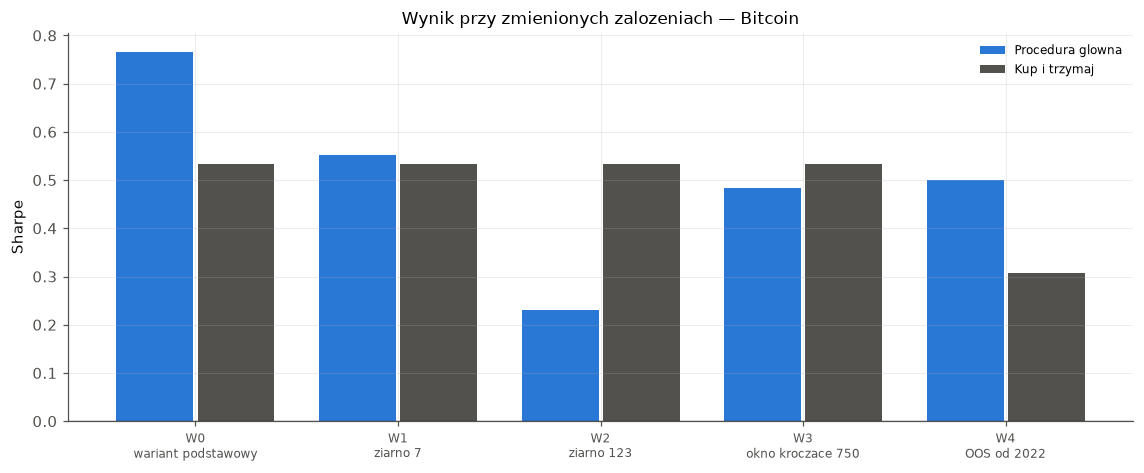

In [33]:
_o = odpornosc.reset_index()
_x = np.arange(len(_o))
fig, ax = plt.subplots(figsize=(10.5, 4.4))
ax.bar(_x - 0.2, _o['Sharpe modelu'], width=0.38, color=KOLORY['procedura'], label='Procedura glowna')
ax.bar(_x + 0.2, _o['Sharpe pasywnie'], width=0.38, color=KOLORY['pasywnie'], label='Kup i trzymaj')
ax.axhline(0, color=KOLORY['tekst'], linewidth=0.8)
ax.set_xticks(_x)
ax.set_xticklabels([s.replace('. ', '\n', 1) for s in _o['Scenariusz']], fontsize=8)
ax.set_ylabel('Sharpe')
ax.set_title(f'Wynik przy zmienionych zalozeniach — {TICKERS[GLOWNY_TK]}')
ax.legend(loc='upper right')
plt.tight_layout()
zapisz_rys('5_2_scenariusze_odpornosci')
plt.show()

## 5.4. Wariancja wynikająca z samej inicjalizacji wag

Sieć LSTM została wyuczona dziesięciokrotnie, każdorazowo z odmienną inicjalizacją wag, przy
niezmienionych pozostałych elementach procedury. Zestawienie obejmuje rozrzut wyników
poszczególnych przebiegów oraz wynik uzyskany po uśrednieniu prawdopodobieństw. Pozycja budowana
jest według konfiguracji stałej, tak aby rozrzut wyników wynikał wyłącznie z inicjalizacji,
a nie z doboru reguły.

Liczba przebiegow  Sharpe — srednia  Odchylenie std     Min    Max  Rozstep  Sharpe po usrednieniu prognoz  Sharpe pasywnie  Udzial przebiegow > pasywna
Instrument Zadanie                                                                                                                                                                        
Bitcoin    ryzyko duzego spadku                  10            0.3042          0.1085  0.1426 0.4367   0.2940                         0.2997           0.5327                       0.0000
           kierunek zmiany (D+1)                 10            0.1268          0.1075 -0.0431 0.2875   0.3306                         0.1110           0.5327                       0.0000

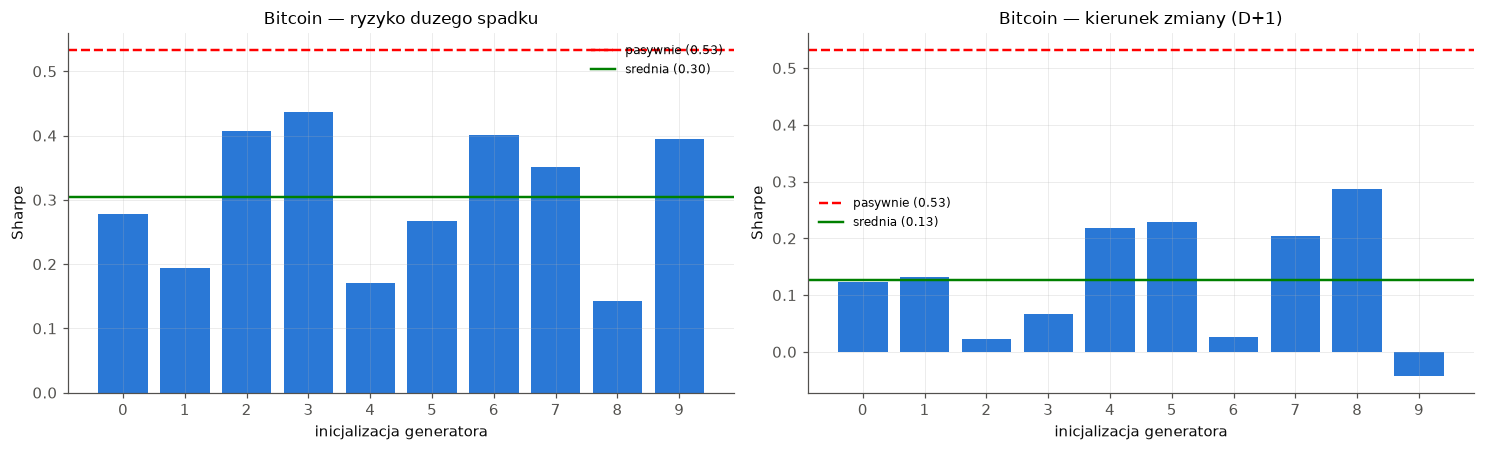

In [34]:
rows, detale = [], []
for key, res in lstm10.items():
    tk, mode = key.split('|')
    oos, seeds = res['oos'], res['seeds']
    y = oos['y_true'].values
    sh = []
    for i, col in enumerate(seeds.columns):
        pr = seeds[col].reindex(oos.index)
        pos = build_positions(oos.assign(_p=pr), tk, '_p', KONFIGURACJA_STALA)
        r, _, _ = backtest(pos, oos, tk)
        s = sharpe_ann(r, tk)
        sh.append(s)
        detale.append({'Instrument': TICKERS.get(tk, tk), 'Zadanie': NAZWA_ZADANIA[mode],
                       'Ziarno': i, 'Sharpe': s,
                       'AUC': roc_auc_score(y, pr.values) if len(np.unique(y)) > 1 else np.nan})
    sh = np.array(sh, dtype=float)
    pos_avg = build_positions(oos, tk, 'proba_LSTM', KONFIGURACJA_STALA)
    r_avg, _, _ = backtest(pos_avg, oos, tk)
    sh_bh_l = sharpe_ann(buy_and_hold(oos, tk)[0], tk)
    rows.append({'Instrument': TICKERS.get(tk, tk), 'Zadanie': NAZWA_ZADANIA[mode],
                 'Liczba przebiegow': len(sh),
                 'Sharpe — srednia': np.nanmean(sh), 'Odchylenie std': np.nanstd(sh, ddof=1),
                 'Min': np.nanmin(sh), 'Max': np.nanmax(sh),
                 'Rozstep': np.nanmax(sh) - np.nanmin(sh),
                 'Sharpe po usrednieniu prognoz': sharpe_ann(r_avg, tk),
                 'Sharpe pasywnie': sh_bh_l,
                 'Udzial przebiegow > pasywna': float(np.nanmean(sh > sh_bh_l))})

lstm_stabilnosc, lstm_detale = pd.DataFrame(rows), pd.DataFrame(detale)
if not lstm_stabilnosc.empty:
    display(lstm_stabilnosc.round(4).set_index(['Instrument', 'Zadanie']))
    fig, axes = plt.subplots(1, len(lstm_stabilnosc),
                             figsize=(6.8 * len(lstm_stabilnosc), 4.2), squeeze=False)
    for ax, (_, row) in zip(axes[0], lstm_stabilnosc.iterrows()):
        sub = lstm_detale[(lstm_detale['Instrument'] == row['Instrument']) &
                          (lstm_detale['Zadanie'] == row['Zadanie'])]
        ax.bar(sub['Ziarno'].astype(str), sub['Sharpe'])
        ax.axhline(row['Sharpe pasywnie'], color='red', linestyle='--',
                   label=f"pasywnie ({row['Sharpe pasywnie']:.2f})")
        ax.axhline(row['Sharpe — srednia'], color='green',
                   label=f"srednia ({row['Sharpe — srednia']:.2f})")
        ax.set_title(f"{row['Instrument']} — {row['Zadanie']}")
        ax.set_xlabel('inicjalizacja generatora')
        ax.set_ylabel('Sharpe')
        ax.legend(fontsize=8)
    plt.tight_layout()
    zapisz_rys('5_3_lstm_inicjalizacje')
    plt.show()

## 5.5. Poziom kosztów transakcyjnych

Strategie aktywne wymagają rotacji kapitału kilkudziesięciokrotnie przewyższającej jego wartość
w skali roku, wobec czego przyjęty poziom opłat wpływa na wynik bezpośrednio. Poniżej zestawiono
wskaźnik Sharpe'a przy pięciu poziomach kosztu od zmiany pozycji oraz wyznaczono poziom, przy
którym model przestaje przewyższać strategię pasywną. Poziom ten jest właściwą miarą ekonomicznej
trwałości wyniku: określa, o ile mogą wzrosnąć opłaty, zanim cała przewaga zostanie wyczerpana.

In [35]:
warianty_kosztow = [
    (f'regula prosta ({MODEL_LABEL[GLOWNY_MODEL]})',
     build_positions(oos_g, GLOWNY_TK, f'proba_{GLOWNY_MODEL}', STRATEGIA_PROSTA)),
    (f'konfiguracja stala ({MODEL_LABEL[GLOWNY_MODEL]})', pos_s),
    ('procedura glowna', pos_g),
]
rows = []
for etykieta, pos in warianty_kosztow:
    row = {'Wariant': etykieta}
    for c in COST_GRID:
        r, _, _ = backtest(pos, oos_g, GLOWNY_TK, cost=c)
        row[f'{c:.2%}'] = sharpe_ann(r, GLOWNY_TK)
    row['Rotacja'] = backtest(pos, oos_g, GLOWNY_TK)[2].sum() / (len(oos_g) / freq_g)
    rows.append(row)

row = {'Wariant': 'kup i trzymaj'}
for c in COST_GRID:
    row[f'{c:.2%}'] = sharpe_ann(buy_and_hold(oos_g, GLOWNY_TK, cost=c)[0], GLOWNY_TK)
row['Rotacja'] = 0.0
rows.append(row)

koszty = pd.DataFrame(rows).set_index('Wariant')
print(f"Wskaznik Sharpe'a przy roznych poziomach kosztu od zmiany pozycji — "
      f"{TICKERS[GLOWNY_TK]}\n")
display(koszty.round(4))

prog_kosztu = np.nan
for c in np.arange(0.0, 0.0081, 0.0001):
    if (sharpe_ann(backtest(pos_g, oos_g, GLOWNY_TK, cost=c)[0], GLOWNY_TK)
            < sharpe_ann(buy_and_hold(oos_g, GLOWNY_TK, cost=c)[0], GLOWNY_TK)):
        prog_kosztu = c
        break
if np.isfinite(prog_kosztu) and prog_kosztu == 0:
    print('\nProcedura glowna nie przewyzsza strategii pasywnej nawet przy zerowym koszcie.')
else:
    print('\nKoszt, przy ktorym procedura glowna przestaje przewyzszac strategie pasywna: '
          + (f'{prog_kosztu:.2%}' if np.isfinite(prog_kosztu) else 'powyzej 0,80%'))
print('Przyjety w badaniu poziom: 0,10%.')

Wskaznik Sharpe'a przy roznych poziomach kosztu od zmiany pozycji — Bitcoin



,0.00%,0.05%,0.10%,0.25%,0.50%,Rotacja
Wariant,,,,,,
regula prosta (XGBoost),0.7944,0.7214,0.6483,0.4290,0.0641,62.4295
konfiguracja stala (XGBoost),0.6727,0.6153,0.5578,0.3852,0.0978,25.1492
procedura glowna,0.8687,0.8176,0.7664,0.6126,0.3560,29.1403
kup i trzymaj,0.5330,0.5328,0.5327,0.5323,0.5316,0.0000



Koszt, przy ktorym procedura glowna przestaje przewyzszac strategie pasywna: 0.33%
Przyjety w badaniu poziom: 0,10%.


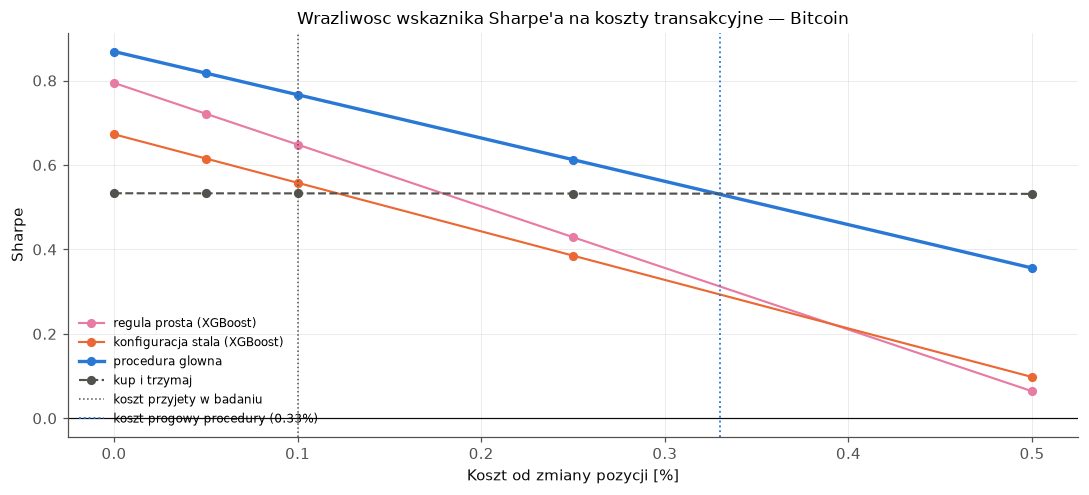

In [36]:
_kx = [c * 100 for c in COST_GRID]
_kol_k = [c for c in koszty.columns if c.endswith('%')]
_styl = {'regula prosta': (KOLORY['prosta'], 1.4, '-'),
         'konfiguracja stala': (KOLORY['stala_konfiguracja'], 1.4, '-'),
         'procedura glowna': (KOLORY['procedura'], 2.2, '-'),
         'kup i trzymaj': (KOLORY['pasywnie'], 1.4, '--')}
fig, ax = plt.subplots(figsize=(10, 4.6))
for w, row in koszty.iterrows():
    kol, lw, ls = next((v for k, v in _styl.items() if w.startswith(k)), ('#4a3aa7', 1.4, '-'))
    ax.plot(_kx, row[_kol_k].values.astype(float), marker='o', markersize=5, color=kol, linewidth=lw,
            linestyle=ls, label=w)
ax.axvline(TRANSACTION_COST * 100, color=KOLORY['pasywnie'], linestyle=':', linewidth=1,
           label='koszt przyjety w badaniu')
if np.isfinite(prog_kosztu) and prog_kosztu > 0:
    ax.axvline(prog_kosztu * 100, color=KOLORY['procedura'], linestyle=':', linewidth=1.2,
               label=f'koszt progowy procedury ({prog_kosztu:.2%})')
ax.axhline(0, color=KOLORY['tekst'], linewidth=0.8)
ax.set_xlabel('Koszt od zmiany pozycji [%]')
ax.set_ylabel('Sharpe')
ax.set_title(f"Wrazliwosc wskaznika Sharpe'a na koszty transakcyjne — {TICKERS[GLOWNY_TK]}")
ax.legend(loc='lower left')
plt.tight_layout()
zapisz_rys('5_4_koszty')
plt.show()

## 5.6. Skład zbioru kandydatów procedury

Procedura główna wymaga jeszcze jednej decyzji, której sama nie rozstrzyga: z jakiego zbioru
kandydatów dokonuje wyboru. Porównano trzy warianty o identycznym mechanizmie selekcji i tej samej
siatce 192 konfiguracji reguły:

1. **wybór modelu z puli trzech modeli** — kandydatami są konfiguracje każdego z modeli, łącznie
   576 wariantów,
2. **średnia prognoz trzech modeli** — prawdopodobieństwa modeli są uśredniane przed zastosowaniem
   reguły, a kandydatami są 192 konfiguracje,
3. **wyłącznie XGBoost** — kandydatami są konfiguracje jednego modelu.

Ostatnia kolumna podaje udział okien, w których procedura wybrała uśrednienie wszystkich
kandydatów, czyli w praktyce zrezygnowała z selekcji. Okna rozruchowe, w których wybór nie był
jeszcze możliwy, pominięto.

In [37]:
rows = []
for w, opis in WARIANTY_PROCEDURY.items():
    for tk in TICKERS:
        if (tk, GLOWNE_ZADANIE) not in wf_results:
            continue
        oos = wf_results[(tk, GLOWNE_ZADANIE)]['oos']
        wyn = procedura_glowna(oos, tk, wariant=w)
        r, p_, t_ = backtest(wyn['pos'], oos, tk)
        met = compute_metrics(r, p_, t_, ticker=tk, asset_returns=oos['next_return'], label='')
        m_bh = compute_metrics(*buy_and_hold(oos, tk), ticker=tk, label='')
        nw = wyn['n_wybrane'].iloc[wyn['okna_rozruchu']:]
        rows.append({'Wariant': opis + (' (glowny)' if w == WARIANT_PROCEDURY else ''),
                     'Instrument': TICKERS[tk], 'Kandydaci': wyn['liczba_kandydatow'],
                     'Zwrot': met['Zwrot'], 'Max obsuniecie': met['Max obsuniecie'],
                     'Calmar': met['Calmar'], 'Sortino': met['Sortino'], 'Sharpe': met['Sharpe'],
                     'Sharpe pasywnie': m_bh['Sharpe'], 'Zaangazowanie': met['Zaangazowanie'],
                     'Rotacja': met['Rotacja'],
                     'Okna bez selekcji': float((nw == wyn['liczba_kandydatow']).mean())})
sklad_puli = pd.DataFrame(rows)
print(f'Sklad zbioru kandydatow procedury — zadanie: {NAZWA_ZADANIA[GLOWNE_ZADANIE]}\n')
display(sklad_puli.round(4).set_index(['Wariant', 'Instrument']))

Sklad zbioru kandydatow procedury — zadanie: ryzyko duzego spadku



Kandydaci   Zwrot  Max obsuniecie  Calmar  Sortino  Sharpe  Sharpe pasywnie  Zaangazowanie  Rotacja  Okna bez selekcji
Wariant                           Instrument                                                                                                                                            
wybor modelu z puli trzech modeli Bitcoin                               576  0.9814         -0.4454  0.2895   0.6739  0.4516           0.5327         0.5103  17.7514             0.8372
                                  S&P 500 (akcje)                       576  0.8274         -0.2473  0.4540   0.8342  0.5820           0.7357         0.7946  13.6919             0.0000
                                  Obligacje skarbowe USA 20+ lat        576 -0.3537         -0.4144 -0.1789  -1.0764 -0.7958          -0.6850         0.8046  17.1196             0.9286
srednia prognoz trzech modeli     Bitcoin                               192  1.6854         -0.4788  0.4000   0.8748  0.5914           0.5327         0.6048  16.9127             0.9767
                                  S&P 500 (akcje)                       192  1.0295         -0.2415  0.5509   0.9651  0.6740           0.7357         0.8944   7.9460             0.0357
                                  Obligacje skarbowe USA 20+ lat        192 -0.3821         -0.4642 -0.1754  -0.9985 -0.7319          -0.6850         0.9337   9.4715             0.7500
wylacznie XGBoost (glowny)        Bitcoin                               192  2.2728         -0.2998  0.7805   1.1910  0.7664           0.5327         0.3932  29.1403             0.2791
                                  S&P 500 (akcje)                       192  0.3864         -0.2185  0.2715   0.3824  0.2689           0.7357         0.5328  22.8232             0.0000
                                  Obligacje skarbowe USA 20+ lat        192 -0.2906         -0.3425 -0.1717  -1.1415 -0.8630          -0.6850         0.5171  28.2417             0.5714

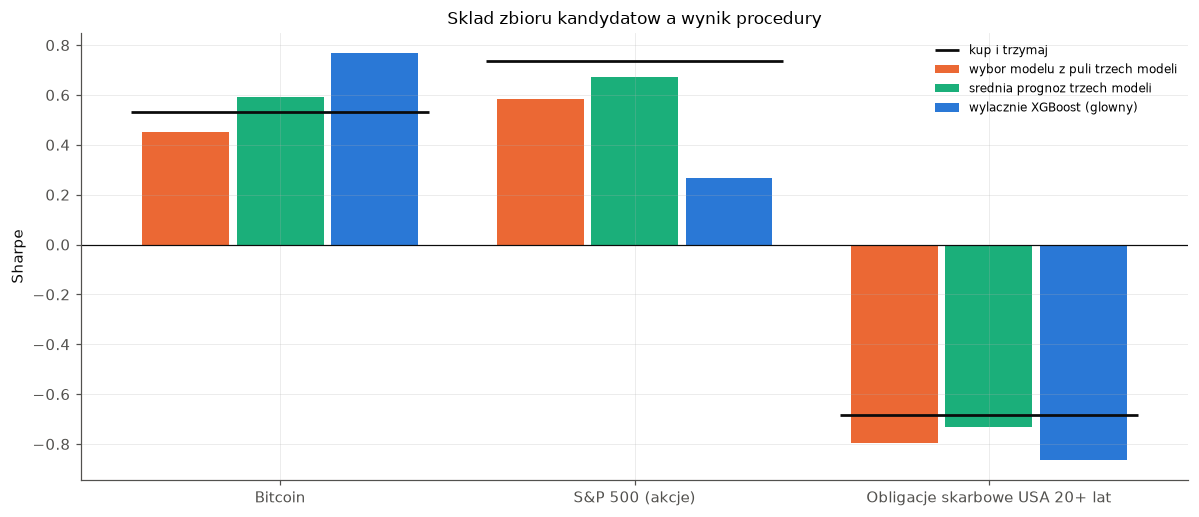

In [38]:
_sp = sklad_puli.copy()
_instr = list(dict.fromkeys(_sp['Instrument']))
_war = list(dict.fromkeys(_sp['Wariant']))
_pozostale = iter([KOLORY['stala_konfiguracja'], KOLORY['stala_ekspozycja'], KOLORY['sma']])
_kol = [KOLORY['procedura'] if '(glowny)' in w else next(_pozostale) for w in _war]
_x = np.arange(len(_instr))
_sz = 0.8 / len(_war)
fig, ax = plt.subplots(figsize=(11, 4.8))
for j, w in enumerate(_war):
    vals = [_sp[(_sp['Wariant'] == w) & (_sp['Instrument'] == i)]['Sharpe'].iloc[0] for i in _instr]
    ax.bar(_x - 0.4 + _sz * (j + 0.5), vals, width=_sz * 0.92, color=_kol[j], label=w)
for xi, i in zip(_x, _instr):
    ax.hlines(_sp[_sp['Instrument'] == i]['Sharpe pasywnie'].iloc[0], xi - 0.42, xi + 0.42,
              color=KOLORY['tekst'], linewidth=1.8, label='kup i trzymaj' if xi == 0 else None)
ax.axhline(0, color=KOLORY['tekst'], linewidth=0.8)
ax.set_xticks(_x)
ax.set_xticklabels(_instr)
ax.set_ylabel('Sharpe')
ax.set_title('Sklad zbioru kandydatow a wynik procedury')
ax.legend(loc='upper right')
plt.tight_layout()
zapisz_rys('5_5_sklad_puli')
plt.show()

**Interpretacja.**

Hipoteza potwierdza się i jest to najlepiej udokumentowany wynik badania, ponieważ każdy z pięciu
eksperymentów opiera się na porównaniu przy niezmienionych danych.

Specyfikacja zbioru zmiennych objaśniających okazuje się najsilniejszym z pięciu czynników.
Zastąpienie czterech zmiennych makroekonomicznych ich pierwszymi różnicami, wymuszone wynikiem
testu ADF, obniżyło wskaźnik Sharpe'a o wartość wielokrotnie przewyższającą przewagę tej
konfiguracji nad strategią pasywną. Wniosek wykracza poza badany przypadek: rezultaty badań opartych na modelach
z niestacjonarnymi zmiennymi objaśniającymi mogą być systematycznie zawyżone, a sam fakt dobrego
dopasowania modelu tego nie sygnalizuje.

Wartości parametrów reguły inwestycyjnej dają rozrzut wskaźnika Sharpe'a szerszy niż odległość
między strategią aktywną a pasywną. Znacząca większość kombinacji przewyższa podejście pasywne,
co wskazuje, że efekt nie jest artefaktem jednego szczególnego zestawu parametrów, lecz cechą
całej klasy rozważanych reguł. Jednocześnie konfiguracja ustalona z góry na krótszej próbie
znalazła się poniżej mediany rozkładu po jego rozszerzeniu. Jest to bezpośrednia, empiryczna
ilustracja problemu przeszukiwania danych: dobór parametrów na podstawie wyników historycznych
nie zachowuje trafności poza próbą, na której został dokonany. Konfiguracja nie została
przestrojona, ponieważ przestrojenie byłoby dokładnie tym błędem, który ta sekcja dokumentuje.

Odpowiedzią proceduralną na ten problem jest procedura główna, w której parametry reguły wyznaczane
są w każdym oknie wyłącznie na podstawie okien wcześniejszych. Jej wynik mieści się w górnej
ćwiartce rozkładu siatki, choć siatka zawiera konfiguracje oceniane z wiedzą o całym okresie
testowym.

Wynik procedury zależy jednak silnie od składu zbioru kandydatów. Przy identycznym mechanizmie
selekcji wskaźnik Sharpe'a na bitcoinie wynosi 0,77 dla zbioru ograniczonego do XGBoosta, 0,59 dla
średniej prognoz trzech modeli i 0,45 dla wyboru z puli wszystkich modeli. Dwa ostatnie warianty
w większości okien wybierały uśrednienie wszystkich kandydatów, czyli w praktyce rezygnowały
z selekcji: przy słabszych modelach w zbiorze najlepiej ocenianą na krótkiej historii opcją
okazywała się dywersyfikacja, która jednocześnie rozcieńczała sygnał XGBoosta. Średnia prognoz jest
dodatkowo obciążona różną skalą prawdopodobieństw — XGBoost uczony z wagami klas wskazuje brak
dużego spadku mniej więcej w połowie sesji, a regresja logistyczna i sieć LSTM w ponad czterech
piątych. Ranking wariantów nie jest przy tym jednolity między rynkami: na rynku akcji i obligacji
wariant ograniczony do XGBoosta wypada najsłabiej. Wariant główny wybrano po przeprowadzeniu tego
porównania, co należy traktować jako kolejną decyzję podjętą na danych z okresu testowego.

Inicjalizacja modelu i schemat treningu rozdzielają dwie kwestie. Zdolność prognostyczna jest
odporna — test Pesarana-Timmermanna dla modelu XGBoost pozostaje istotny w czterech z pięciu
scenariuszy, a w piątym, przy przesunięciu okresu testowego o rok, pozostaje graniczny. Odporna
jest również redukcja obsunięcia kapitału. Wynik inwestycyjny procedury głównej zmienia się natomiast
między scenariuszami wyraźniej niż zdolność prognostyczna: wskaźnik Sharpe'a waha się od 0,23 do
0,77, a przewaga nad strategią pasywną utrzymuje się w trzech z pięciu scenariuszy, mimo że zmiana ziarna
generatora liczb pseudolosowych nie oznacza żadnej zmiany ani w danych, ani w procedurze.

Dziesięć przebiegów sieci LSTM pokazuje to samo w formie skrajnej. Rozstęp wskaźnika Sharpe'a
między inicjalizacjami tej samej sieci przewyższa różnice obserwowane między odmiennymi
architekturami modeli, a odchylenie standardowe między przebiegami jest porównywalne z wartością
średnią. Wynika z tego wniosek metodologiczny: raportowanie rezultatu pojedynczego przebiegu
sieci neuronowej, praktyka rozpowszechniona w literaturze przedmiotu, nie stanowi wiarygodnej
podstawy wnioskowania. Uśrednienie prognoz z wielu inicjalizacji redukuje wariancję, lecz nie
podnosi wyniku powyżej poziomu strategii pasywnej.

Poziom kosztów transakcyjnych wyznacza granicę stosowalności. Przyjęte w badaniu 0,1% od zmiany
pozycji jest realistyczne dla giełd kryptowalut, lecz nie dla wszystkich rachunków dostępnych
inwestorom indywidualnym. Przewaga procedury głównej zanika dopiero przy koszcie około 0,33% od zmiany
pozycji, czyli ponad trzykrotnie wyższym od przyjętego w badaniu, przewaga konfiguracji stałej zanika już między 0,1% a 0,25%,
a przy koszcie 0,5% strategia pasywna przewyższa każdy z wariantów aktywnych. Jest to ograniczenie o charakterze praktycznym,
niezależne od istotności statystycznej.

---

# 6. Wnioski

## Weryfikacja hipotez

**H1 — zdolność prognostyczna zależy od rynku i od sformułowania zadania: potwierdzona
warunkowo.**
Zdolność prognozowania kierunku zmiany ceny w horyzoncie jednej sesji pozostaje na wszystkich
trzech rynkach bliska poziomu losowego, a pojedyncze wyniki istotne przy poziomie 5% nie utrzymują
się po korekcie na liczbę przeprowadzonych testów. Ryzyko dużego spadku, definiowane jako strata
przekraczająca wielokrotność bieżącej zmienności, jest prognozowalne na bitcoinie i na rynku
akcji, przy czym tylko jedna kombinacja w całym zestawieniu pozostaje istotna po tej korekcie.
Zależność występuje konsekwentnie dla regresji logistycznej, dla XGBoosta poza rynkiem obligacji,
i nie występuje dla sieci LSTM. Weryfikacja na Ethereum nie potwierdza wyniku bitcoinowego, co ogranicza
wnioskowanie do jednego instrumentu, nie do klasy aktywów.

**H2 — oddziaływanie na profil ryzyka, nie na stopę zwrotu: potwierdzona.**
Redukcja maksymalnego obsunięcia i zmienności jest na bitcoinie znaczna, na obligacjach umiarkowana,
a na rynku akcji, gdzie obsunięcie strategii pasywnej jest umiarkowane, niewielka i okupiona
wyraźnie niższą stopą zwrotu. Na bitcoinie procedura uzyskuje również wyższą stopę zwrotu niż
strategia pasywna, lecz różnica wskaźnika Sharpe'a nie jest istotna statystycznie i pozostaje
wrażliwa na koszty oraz na strukturę faz rynku. Porównanie ze strategią o stałej, obniżonej
ekspozycji wykazuje, że wybór momentów wnosi wartość dodaną ponad samo zmniejszenie zaangażowania,
choć część efektu jest osiągalna bez żadnego modelu.

**H3 — ocena efektywności jest wrażliwa na decyzje metodologiczne: potwierdzona.**
Każdy z pięciu przebadanych czynników — specyfikacja zbioru zmiennych, wartości parametrów
reguły, skład zbioru kandydatów procedury, inicjalizacja modelu i poziom kosztów — przesuwa wskaźnik Sharpe'a w zakresie
porównywalnym z różnicą między strategiami aktywnymi a pasywną lub szerszym i może zmieniać ranking
strategii. W przypadku
zmiennych niestacjonarnych i inicjalizacji generatora dane pozostają przy tym identyczne.
Procedura wyznaczająca parametry na bieżąco ogranicza wrażliwość na parametry reguły, lecz jej
wynik zależy od składu zbioru kandydatów.

## Wniosek końcowy

Badane modele wykazują statystycznie istotną zdolność prognostyczną, warunkowaną rynkiem oraz
sposobem sformułowania zadania: prognozowalne okazuje się ryzyko, nie kierunek zmiany ceny.
Zdolność ta przekłada się na wymierną poprawę profilu ryzyka tam, gdzie ryzyko pasywnej
ekspozycji jest wysokie — dla bitcoina maksymalne obsunięcie kapitału zostaje ograniczone o ponad
połowę — natomiast na rynku o umiarkowanym obsunięciu poprawa jest niewielka lub nie występuje.
Przewaga w stopie zwrotu i wskaźniku Sharpe'a jest natomiast nieistotna statystycznie i wrażliwa
na poziom kosztów. Część tej poprawy jest przy tym osiągalna
bez żadnego modelu, przez samo utrzymywanie mniejszej pozycji.

Odpowiedź na pytanie badawcze ma zatem charakter warunkowy. Aktywne strategie oparte na uczeniu
maszynowym mogą stanowić narzędzie ograniczania ryzyka na rynkach o wysokiej zmienności, nie dają
natomiast podstaw do twierdzenia o trwałej przewadze w stopie zwrotu. Uzyskiwane rezultaty są przy tym silnie wrażliwe
na decyzje metodologiczne, co jest
wnioskiem odnoszącym się nie tylko do niniejszego badania, lecz do całej klasy badań tego typu.

## Ograniczenia

**Brak istotności statystycznej przewagi.** Zdolność prognostyczna jest istotna, przewaga
w stopie zwrotu skorygowanej o zmienność — nie. Przy zmienności bitcoina przedziały ufności
wskaźnika Sharpe'a są zbyt szerokie, aby rozstrzygać różnice obserwowanej wielkości. Przewaga
w miarach uwzględniających głębokość obsunięć jest wyraźniejsza, lecz dla nich nie istnieją
równie ugruntowane testy istotności.

**Wybór wariantu procedury.** Wariant główny wybrano po porównaniu trzech składów zbioru
kandydatów na tym samym okresie testowym. Deflated Sharpe Ratio uwzględnia wszystkie przebadane
warianty, lecz wynik wariantu głównego należy traktować jako optymistyczny względem tego, czego
można oczekiwać na nowych danych.

**Zakres wnioskowania.** Wynik dotyczy jednego instrumentu, nie klasy aktywów, ponieważ nie
powtarza się na Ethereum. Nie sprawdzono, czy utrzymuje się na kolejnych kryptowalutach.

**Długość próby.** Okres testowy obejmuje niespełna sześć lat i jeden pełny cykl rynku
kryptowalut. Bilans wymiany między ochroną przed spadkami a udziałem we wzrostach zależy od
struktury faz rynkowych w badanym okresie i nie musi się powtórzyć.

**Poziom kosztów.** Przyjęty poziom 0,1% od zmiany pozycji jest realistyczny dla giełd
kryptowalut, lecz nie dla wszystkich rachunków dostępnych inwestorom indywidualnym. Przewaga
procedury głównej zanika przy koszcie około 0,33% od zmiany pozycji, a konfiguracji stałej — już
między 0,1% a 0,25%.

**Wąskość efektu w obrębie modeli.** Konieczne jest tu rozdzielenie dwóch rzeczy. Zdolność
prognostyczna występuje zarówno dla regresji logistycznej, jak i dla XGBoosta, natomiast przewaga
inwestycyjna konfiguracji stałej nad strategią pasywną — wyłącznie dla XGBoosta; regresja
logistyczna, mimo istotnego wyniku testu Pesarana-Timmermanna, nie przewyższa podejścia pasywnego.
Procedura główna korzysta wyłącznie z prognoz XGBoosta, który na rynku akcji i obligacji wypada
w niej najsłabiej spośród porównywanych wariantów (sekcja 5.6). Dla sieci rekurencyjnej nie
występuje ani jedno, ani drugie, przy czym jej wyniki są obciążone wariancją inicjalizacji na tyle
dużą, że nie pozwalają na jednoznaczne wnioskowanie o samej architekturze.

---

---

# Aneks

Wyniki uzupełniające, nieomawiane w części głównej. Zostały policzone i zachowane, aby procedurę
dało się sprawdzić w całości, lecz nie wnoszą treści do weryfikacji trzech hipotez. Pełna
implementacja znajduje się w pliku `implementacja.ipynb`.

## A1. Pozostałe sformułowania zadania prognostycznego

Prognoza kierunku w horyzoncie pięciu sesji oraz metoda barier zmiennościowych, w której etykieta
zależy od tego, który z poziomów granicznych — wyznaczonych jako wielokrotność bieżącej
zmienności — zostanie osiągnięty jako pierwszy.

In [39]:
rows = []
for (tk, mode), res in wf_results.items():
    if mode not in ZADANIA_ANEKS or tk == TICKER_WERYFIKACYJNY:
        continue
    oos = res['oos']
    y = oos['y_true'].values
    for m in MODELS:
        p = oos[f'proba_{m}'].values
        pos = build_positions(oos, tk, f'proba_{m}', KONFIGURACJA_STALA)
        r, p_, t_ = backtest(pos, oos, tk)
        met = compute_metrics(r, p_, t_, ticker=tk, asset_returns=oos['next_return'], label='')
        pt = pesaran_timmermann(y, (p > 0.5).astype(int))
        rows.append({'Instrument': TICKERS[tk], 'Zadanie': NAZWA_ZADANIA[mode],
                     'Model': MODEL_LABEL[m],
                     'AUC': roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan,
                     'Test PT (p)': pt['p_value'], 'Sharpe': met['Sharpe'],
                     'Zwrot': met['Zwrot'], 'Max obsuniecie': met['Max obsuniecie']})
zadania_aneks = pd.DataFrame(rows)
display(zadania_aneks.round(4).reset_index(drop=True))

,Instrument,Zadanie,Model,AUC,Test PT (p),Sharpe,Zwrot,Max obsuniecie
0,Bitcoin,kierunek zmiany (D+5),Regresja logistyczna,0.5239,0.0045,0.4875,1.0501,-0.5371
1,Bitcoin,kierunek zmiany (D+5),XGBoost,0.5374,0.0014,0.2253,0.3797,-0.4917
2,Bitcoin,kierunek zmiany (D+5),LSTM,0.5362,0.0100,-0.0581,-0.0744,-0.4342
3,Bitcoin,bariery zmiennosciowe,Regresja logistyczna,0.5102,0.2458,0.0938,0.1522,-0.5766
4,Bitcoin,bariery zmiennosciowe,XGBoost,0.5003,0.2103,0.5400,1.2419,-0.4522
5,Bitcoin,bariery zmiennosciowe,LSTM,0.5064,0.8129,-0.0820,-0.1040,-0.4577
6,S&P 500 (akcje),kierunek zmiany (D+5),Regresja logistyczna,0.4845,0.6319,0.3629,0.5313,-0.2337
7,S&P 500 (akcje),kierunek zmiany (D+5),XGBoost,0.5034,0.7432,0.3382,0.4682,-0.2354
8,S&P 500 (akcje),kierunek zmiany (D+5),LSTM,0.5283,0.0163,0.6733,0.9468,-0.1849
9,S&P 500 (akcje),bariery zmiennosciowe,Regresja logistyczna,0.4986,0.1780,0.5044,0.6987,-0.2132


## A2. Pozostałe warianty reguły inwestycyjnej

Osiem sposobów przekształcenia prawdopodobieństwa w pozycję, zastosowanych do konfiguracji
o najwyższej zdolności prognostycznej.

In [40]:
rows = []
for nazwa, cfg in WARIANTY_ANEKS.items():
    pos = build_positions(oos_g, GLOWNY_TK, f'proba_{GLOWNY_MODEL}', cfg)
    r, p_, t_ = backtest(pos, oos_g, GLOWNY_TK, cost=TRANSACTION_COST,
                         stop_loss=cfg.get('stop_loss'))
    row = compute_metrics(r, p_, t_, ticker=GLOWNY_TK, asset_returns=oos_g['next_return'],
                          label=('konfiguracja stala' if nazwa == 'konfiguracja glowna' else nazwa))
    for c in [0.0025, 0.005]:
        rc, _, _ = backtest(pos, oos_g, GLOWNY_TK, cost=c, stop_loss=cfg.get('stop_loss'))
        row[f'Sharpe @ {c:.2%}'] = sharpe_ann(rc, GLOWNY_TK)
    rows.append(row)

row = compute_metrics(bh_g[0], bh_g[1], bh_g[2], ticker=GLOWNY_TK, label='kup i trzymaj')
for c in [0.0025, 0.005]:
    row[f'Sharpe @ {c:.2%}'] = sharpe_ann(buy_and_hold(oos_g, GLOWNY_TK, cost=c)[0], GLOWNY_TK)
rows.append(row)

warianty_regul = pd.DataFrame(rows)[
    ['Strategia', 'Zwrot', 'Zmiennosc', 'Sharpe', 'Max obsuniecie', 'Zaangazowanie',
     'Rotacja', 'Sharpe @ 0.25%', 'Sharpe @ 0.50%']]
display(warianty_regul.round(4).reset_index(drop=True))

,Strategia,Zwrot,Zmiennosc,Sharpe,Max obsuniecie,Zaangazowanie,Rotacja,Sharpe @ 0.25%,Sharpe @ 0.50%
0,"próg 0,50",2.4373,0.4276,0.6483,-0.4359,0.4932,62.4295,0.4290,0.0641
1,"próg 0,55",2.0269,0.3980,0.6087,-0.3753,0.4261,63.4937,0.3691,-0.0293
2,próg dobierany kroczaco,1.5808,0.4279,0.5299,-0.5242,0.5034,63.8484,0.3057,-0.0667
3,skalowanie pozycji,1.0409,0.3372,0.4461,-0.3109,0.3400,59.2554,0.1824,-0.2562
4,kontrola zmiennosci,1.0141,0.2118,0.5382,-0.2202,0.2738,44.0458,0.2258,-0.2916
5,filtr SMA200,0.6728,0.3230,0.3416,-0.3980,0.2862,43.6297,0.1389,-0.1980
6,stop-loss 7%,0.7950,0.4313,0.3786,-0.5141,0.4932,62.4295,0.1614,-0.1999
7,konfiguracja stala,1.0900,0.2188,0.5578,-0.3518,0.3194,25.1492,0.3852,0.0978
8,kup i trzymaj,1.6644,0.5730,0.5327,-0.7663,1.0000,0.1774,0.5323,0.5316


## A3. Wrażliwość procedury głównej na liczbę uśrednianych wariantów

Zestawienie podaje wyniki, jakie dałaby procedura główna przy każdej ze stałych wartości liczby
uśrednianych wariantów, spośród których procedura wybiera na bieżąco. Porównanie składów zbioru
kandydatów przedstawiono w sekcji 5.6. Wartości te służą wyłącznie ocenie wrażliwości. Żadna z nich
nie była podstawą konstrukcji procedury, a wybór jednej z nich na podstawie tej tabeli oznaczałby
dobór parametru na okresie testowym.

In [41]:
K_g = wynik_g['liczba_kandydatow']
pozycje_a3 = [(f'stale n = {K_g if n is None else n}' + (' (wszystkie)' if n is None else ''), p)
              for n, p in wynik_g['warianty'].items()]
pozycje_a3 += [('procedura glowna (n wybierane kroczaco)', pos_g),
               (f'konfiguracja stala ({MODEL_LABEL[GLOWNY_MODEL]})', pos_s)]

rows = []
for label, pos in pozycje_a3:
    r, p_, t_ = backtest(pos, oos_g, GLOWNY_TK)
    row = compute_metrics(r, p_, t_, ticker=GLOWNY_TK, asset_returns=oos_g['next_return'],
                          label=label)
    for c in [0.0025, 0.005]:
        row[f'Sharpe @ {c:.2%}'] = sharpe_ann(backtest(pos, oos_g, GLOWNY_TK, cost=c)[0],
                                              GLOWNY_TK)
    rows.append(row)

row = compute_metrics(bh_g[0], bh_g[1], bh_g[2], ticker=GLOWNY_TK, label='kup i trzymaj')
for c in [0.0025, 0.005]:
    row[f'Sharpe @ {c:.2%}'] = sharpe_ann(buy_and_hold(oos_g, GLOWNY_TK, cost=c)[0], GLOWNY_TK)
rows.append(row)

wrazliwosc_procedury = pd.DataFrame(rows)[
    ['Strategia', 'Zwrot', 'CAGR', 'Max obsuniecie', 'Calmar', 'Sortino', 'Sharpe',
     'Zmiennosc', 'Zaangazowanie', 'Rotacja', 'Sharpe @ 0.25%', 'Sharpe @ 0.50%']]
display(wrazliwosc_procedury.round(4).reset_index(drop=True))

_sh = wrazliwosc_procedury.set_index('Strategia')['Sharpe']
_stale = _sh[[s for s in _sh.index if s.startswith('stale n')]]
print(f"\nZakres wskaznika Sharpe przy stalej liczbie usrednianych wariantow: "
      f"[{_stale.min():.4f}, {_stale.max():.4f}]")
print(f"Procedura glowna: {_sh['procedura glowna (n wybierane kroczaco)']:.4f} | "
      f"kup i trzymaj: {_sh['kup i trzymaj']:.4f}")

,Strategia,Zwrot,CAGR,Max obsuniecie,Calmar,Sortino,Sharpe,Zmiennosc,Zaangazowanie,Rotacja,Sharpe @ 0.25%,Sharpe @ 0.50%
0,stale n = 1,2.6131,0.2559,-0.3421,0.7480,1.2450,0.7889,0.3068,0.4019,30.6409,0.6388,0.3885
1,stale n = 5,2.2125,0.2300,-0.3216,0.7152,1.2049,0.7690,0.2761,0.3737,29.0550,0.6111,0.3476
2,stale n = 10,2.0344,0.2176,-0.2960,0.7351,1.2009,0.7704,0.2554,0.3503,28.2272,0.6046,0.3279
3,stale n = 20,1.8880,0.2069,-0.2995,0.6910,1.1252,0.7233,0.2624,0.3669,29.1450,0.5567,0.2787
4,stale n = 50,1.7150,0.1938,-0.2695,0.7192,1.0502,0.6770,0.2652,0.3736,29.4845,0.5103,0.2322
5,stale n = 192 (wszystkie),1.6217,0.1864,-0.2876,0.6481,1.0418,0.6741,0.2522,0.3512,26.5836,0.5159,0.2523
6,procedura glowna (n wybierane kroczaco),2.2728,0.2340,-0.2998,0.7805,1.1910,0.7664,0.2844,0.3932,29.1403,0.6126,0.3560
7,konfiguracja stala (XGBoost),1.0900,0.1397,-0.3518,0.3970,0.8446,0.5578,0.2188,0.3194,25.1492,0.3852,0.0978
8,kup i trzymaj,1.6644,0.1898,-0.7663,0.2477,0.7846,0.5327,0.5730,1.0000,0.1774,0.5323,0.5316



Zakres wskaznika Sharpe przy stalej liczbie usrednianych wariantow: [0.6741, 0.7889]
Procedura glowna: 0.7664 | kup i trzymaj: 0.5327


## A4. Poziom portfela

Wariant, w którym wagi składników portfela o strukturze 60% akcje i 40% obligacje są mnożone przez
decyzję odpowiadającego im modelu w konfiguracji stałej.

In [42]:
rows = []
for nazwa, wagi in [('60/40', {'SPY': 0.6, 'TLT': 0.4}),
                    ('55/35/10 z BTC', {'SPY': 0.55, 'TLT': 0.35, 'BTC-USD': 0.10})]:
    res = portfolio_backtest(wagi, zadanie=GLOWNE_ZADANIE)
    if res:
        rows.append(compute_metrics(*res, ticker='SPY', label=f'{nazwa} — pasywnie'))
    for m in MODELS:
        pos_d = {}
        for tk in wagi:
            k = [(t, mo) for (t, mo) in wf_results if t == tk and mo == GLOWNE_ZADANIE]
            if not k:
                continue
            pos_d[tk] = build_positions(wf_results[k[0]]['oos'], tk, f'proba_{m}',
                                        KONFIGURACJA_STALA)
        res = portfolio_backtest(wagi, pos_d, zadanie=GLOWNE_ZADANIE)
        if res:
            rows.append(compute_metrics(*res, ticker='SPY',
                                        label=f'{nazwa} — sterowany przez {MODEL_LABEL[m]}'))

portfel = pd.DataFrame(rows)[['Strategia', 'Zwrot', 'CAGR', 'Zmiennosc', 'Sharpe',
                              'Max obsuniecie', 'Calmar', 'Zaangazowanie', 'Rotacja']]
display(portfel.round(4).reset_index(drop=True))

,Strategia,Zwrot,CAGR,Zmiennosc,Sharpe,Max obsuniecie,Calmar,Zaangazowanie,Rotacja
0,60/40 — pasywnie,0.3787,0.0583,0.1217,0.2583,-0.2724,0.2141,1.0000,0.1765
1,60/40 — sterowany przez Regresja logistyczna,0.3197,0.0502,0.1125,0.2012,-0.2694,0.1863,0.8734,12.2674
2,60/40 — sterowany przez XGBoost,0.0543,0.0094,0.0912,-0.2100,-0.2363,0.0397,0.5623,25.6256
3,60/40 — sterowany przez LSTM,0.3108,0.0489,0.1173,0.1875,-0.2738,0.1786,0.9207,7.3441
4,55/35/10 z BTC — pasywnie,0.4581,0.0695,0.1321,0.3280,-0.3100,0.2242,1.0000,0.1782
5,55/35/10 z BTC — sterowany przez Regresja logi...,0.3518,0.0552,0.1104,0.2466,-0.2671,0.2066,0.8406,12.9184
6,55/35/10 z BTC — sterowany przez XGBoost,0.1131,0.0193,0.0880,-0.1095,-0.2256,0.0855,0.5436,25.4198
7,55/35/10 z BTC — sterowany przez LSTM,0.3235,0.0512,0.1159,0.2076,-0.2776,0.1845,0.8834,8.2859


## A5. Pełne zestawienie metryk

Wszystkie kombinacje instrumentu, zadania, modelu i reguły inwestycyjnej z części głównej.

In [43]:
for tk in TICKERS:
    for mode in ZADANIA_GLOWNE:
        sub = metryki_pelne[(metryki_pelne['_tk'] == tk) & (metryki_pelne['_mode'] == mode)]
        if sub.empty:
            continue
        print(f"\n{'='*100}\n{TICKERS[tk]} — {NAZWA_ZADANIA[mode]}\n{'='*100}")
        display(sub[KOL].round(4).reset_index(drop=True))


Bitcoin — kierunek zmiany (D+1)


,Strategia,Zwrot,CAGR,Max obsuniecie,Calmar,Sortino,Sharpe,Zmiennosc,Zaangazowanie,Rotacja
0,Kup i trzymaj,1.6644,0.1898,-0.7663,0.2477,0.7846,0.5327,0.5730,1.0000,0.1774
1,Filtr SMA200,1.7329,0.1952,-0.6432,0.3035,0.8417,0.5581,0.4139,0.5408,9.3999
2,Regresja logistyczna — regula prosta,0.2755,0.0441,-0.7889,0.0559,0.3641,0.2508,0.4547,0.5554,62.4295
3,Regresja logistyczna — konfiguracja stala,1.2926,0.1585,-0.4357,0.3638,0.8572,0.5720,0.2587,0.3760,24.0641
4,XGBoost — regula prosta,1.0683,0.1376,-0.6405,0.2148,0.6532,0.4388,0.4611,0.5573,104.1084
5,XGBoost — konfiguracja stala,1.1247,0.1430,-0.4556,0.3139,0.7364,0.4981,0.2835,0.4117,32.1573
6,LSTM — regula prosta,-0.0311,-0.0056,-0.7390,-0.0076,0.1941,0.1364,0.4434,0.4796,53.9164
7,LSTM — konfiguracja stala,0.1747,0.0290,-0.4546,0.0637,0.1587,0.1127,0.2563,0.3227,23.3112
8,Procedura glowna,1.2246,0.1524,-0.4948,0.3079,0.7611,0.5190,0.2934,0.4326,35.5285



Bitcoin — ryzyko duzego spadku


,Strategia,Zwrot,CAGR,Max obsuniecie,Calmar,Sortino,Sharpe,Zmiennosc,Zaangazowanie,Rotacja
0,Kup i trzymaj,1.6644,0.1898,-0.7663,0.2477,0.7846,0.5327,0.5730,1.0000,0.1774
1,Filtr SMA200,1.7329,0.1952,-0.6432,0.3035,0.8417,0.5581,0.4139,0.5408,9.3999
2,Regresja logistyczna — regula prosta,1.8492,0.2041,-0.7088,0.2879,0.8246,0.5538,0.5182,0.8654,30.3280
3,Regresja logistyczna — konfiguracja stala,1.2778,0.1572,-0.4806,0.3271,0.7849,0.5230,0.3062,0.5781,19.1230
4,XGBoost — regula prosta,2.4373,0.2448,-0.4359,0.5616,1.0019,0.6483,0.4276,0.4932,62.4295
5,XGBoost — konfiguracja stala,1.0900,0.1397,-0.3518,0.3970,0.8446,0.5578,0.2188,0.3194,25.1492
6,LSTM — regula prosta,0.3197,0.0504,-0.7528,0.0670,0.4384,0.3028,0.5443,0.8834,19.8639
7,LSTM — konfiguracja stala,0.6956,0.0982,-0.5543,0.1771,0.5080,0.3521,0.3095,0.5593,17.3982
8,Procedura glowna,2.2728,0.2340,-0.2998,0.7805,1.1910,0.7664,0.2844,0.3932,29.1403



S&P 500 (akcje) — kierunek zmiany (D+1)


,Strategia,Zwrot,CAGR,Max obsuniecie,Calmar,Sortino,Sharpe,Zmiennosc,Zaangazowanie,Rotacja
0,Kup i trzymaj,1.2297,0.1520,-0.2450,0.6205,1.0633,0.7357,0.1669,1.0000,0.1765
1,Filtr SMA200,0.9329,0.1233,-0.1992,0.6190,1.0957,0.7810,0.1157,0.8081,5.4706
2,Regresja logistyczna — regula prosta,0.3748,0.0578,-0.2251,0.2567,0.3503,0.2377,0.1401,0.6359,52.7647
3,Regresja logistyczna — konfiguracja stala,0.6555,0.0930,-0.2649,0.3511,0.6687,0.4620,0.1445,0.6783,20.2521
4,XGBoost — regula prosta,0.1965,0.0322,-0.2657,0.1211,0.0915,0.0629,0.1406,0.6169,76.2353
5,XGBoost — konfiguracja stala,0.4705,0.0704,-0.2751,0.2560,0.4514,0.3137,0.1474,0.7072,31.8862
6,LSTM — regula prosta,0.8410,0.1137,-0.1646,0.6908,0.9191,0.6103,0.1387,0.5357,35.1176
7,LSTM — konfiguracja stala,0.7307,0.1016,-0.1909,0.5324,0.7762,0.5272,0.1403,0.5762,21.8421
8,Procedura glowna,0.4334,0.0656,-0.2733,0.2400,0.4160,0.2903,0.1402,0.7201,26.8656


... (2 outputs left out)


Obligacje skarbowe USA 20+ lat — kierunek zmiany (D+1)


,Strategia,Zwrot,CAGR,Max obsuniecie,Calmar,Sortino,Sharpe,Zmiennosc,Zaangazowanie,Rotacja
0,Kup i trzymaj,-0.3819,-0.0814,-0.4370,-0.1863,-0.9415,-0.6850,0.1542,1.0000,0.1765
1,Filtr SMA200,-0.3944,-0.0847,-0.4057,-0.2088,-1.8279,-1.4465,0.0815,0.3508,18.0000
2,Regresja logistyczna — regula prosta,-0.3430,-0.0715,-0.3672,-0.1946,-1.1604,-0.8489,0.1176,0.5469,62.8235
3,Regresja logistyczna — konfiguracja stala,-0.2911,-0.0589,-0.3696,-0.1594,-0.9312,-0.6789,0.1258,0.6345,29.2941
4,XGBoost — regula prosta,-0.3294,-0.0681,-0.3394,-0.2006,-1.1953,-0.8656,0.1119,0.5168,85.7647
5,XGBoost — konfiguracja stala,-0.2673,-0.0534,-0.3752,-0.1423,-0.8887,-0.6393,0.1247,0.6506,36.0000
6,LSTM — regula prosta,-0.1843,-0.0353,-0.2707,-0.1304,-0.7571,-0.5447,0.1140,0.5525,42.8824
7,LSTM — konfiguracja stala,-0.2007,-0.0388,-0.2993,-0.1295,-0.7428,-0.5342,0.1213,0.6190,30.5294
8,Procedura glowna,-0.1828,-0.0350,-0.2992,-0.1170,-0.8107,-0.5843,0.1070,0.4685,38.4676



Obligacje skarbowe USA 20+ lat — ryzyko duzego spadku


,Strategia,Zwrot,CAGR,Max obsuniecie,Calmar,Sortino,Sharpe,Zmiennosc,Zaangazowanie,Rotacja
0,Kup i trzymaj,-0.3819,-0.0814,-0.4370,-0.1863,-0.9415,-0.6850,0.1542,1.0000,0.1765
1,Filtr SMA200,-0.3944,-0.0847,-0.4057,-0.2088,-1.8279,-1.4465,0.0815,0.3508,18.0000
2,Regresja logistyczna — regula prosta,-0.3927,-0.0842,-0.4414,-0.1909,-1.0345,-0.7610,0.1448,0.8992,24.8824
3,Regresja logistyczna — konfiguracja stala,-0.3525,-0.0738,-0.4051,-0.1823,-0.9014,-0.6563,0.1496,0.9419,13.2353
4,XGBoost — regula prosta,-0.2815,-0.0567,-0.3127,-0.1812,-1.0970,-0.8249,0.1038,0.4699,55.4118
5,XGBoost — konfiguracja stala,-0.1711,-0.0326,-0.3001,-0.1086,-0.7385,-0.5460,0.1095,0.5434,25.0588
6,LSTM — regula prosta,-0.3894,-0.0834,-0.4550,-0.1832,-1.0051,-0.7381,0.1474,0.9132,13.2353
7,LSTM — konfiguracja stala,-0.3484,-0.0728,-0.4383,-0.1661,-0.8919,-0.6495,0.1494,0.9314,8.6471
8,Procedura glowna,-0.2906,-0.0588,-0.3425,-0.1717,-1.1415,-0.8630,0.1020,0.5171,28.2417


## A6. Pełna tabela stacjonarności

Test ADF dla wszystkich zmiennych objaśniających, wraz ze zmiennymi kalendarzowymi wyłączonymi
z zestawienia w sekcji 1.3, oraz porównanie wybranych szeregów w postaciach surowej
i przeskalowanej.

In [44]:
if OPT['statsmodels']:
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for tk in TICKERS:
            d = feature_data[tk]
            for f in FEATURES_BY_TICKER[tk]:
                out = adf_summary(d[f], f)
                if out:
                    out['Instrument'] = TICKERS[tk]
                    out['Grupa'] = ('kalendarzowe' if f in ZMIENNE_KALENDARZOWE
                                    else grupa_zmiennej(f))
                    rows.append(out)
    adf_pelne = pd.DataFrame(rows)
    print(f'Przetestowano {len(adf_pelne)} zmiennych.\n')
    display(adf_pelne.pivot_table(index='Instrument', columns='Grupa',
                                  values='Stacjonarna', aggfunc='mean').round(3))

    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for tk in TICKERS:
            c = raw_data[tk]['Close']
            macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
            for nazwa, s in [('Cena (poziom)', c),
                             ('Log-zwrot dzienny', np.log(c / c.shift(1))),
                             ('MACD nominalny', macd), ('MACD / cena', macd / c)]:
                out = adf_summary(s, nazwa)
                if out:
                    out['Instrument'] = TICKERS[tk]
                    rows.append(out)
    print('\nPorownanie wybranych szeregow:\n')
    display(pd.DataFrame(rows)[['Instrument', 'Zmienna', 'ADF', 'p-value', 'Stacjonarna']]
            .round(4).reset_index(drop=True))

Przetestowano 279 zmiennych.



Grupa,kalendarzowe,rynkowe i makroekonomiczne,sieciowe i sentyment,techniczne
Instrument,,,,
Bitcoin,0.7500,1.0000,1.0000,1.0000
Obligacje skarbowe USA 20+ lat,1.0000,1.0000,NaN,0.9290
S&P 500 (akcje),1.0000,1.0000,NaN,1.0000



Porownanie wybranych szeregow:



,Instrument,Zmienna,ADF,p-value,Stacjonarna
0,Bitcoin,Cena (poziom),-1.0046,0.7516,False
1,Bitcoin,Log-zwrot dzienny,-41.2825,0.0000,True
2,Bitcoin,MACD nominalny,-7.4278,0.0000,True
3,Bitcoin,MACD / cena,-6.9359,0.0000,True
4,S&P 500 (akcje),Cena (poziom),0.9878,0.9941,False
5,S&P 500 (akcje),Log-zwrot dzienny,-15.7680,0.0000,True
6,S&P 500 (akcje),MACD nominalny,-8.1363,0.0000,True
7,S&P 500 (akcje),MACD / cena,-8.7573,0.0000,True
8,Obligacje skarbowe USA 20+ lat,Cena (poziom),-1.0784,0.7236,False
9,Obligacje skarbowe USA 20+ lat,Log-zwrot dzienny,-9.5846,0.0000,True


## A7. Ważność zmiennych objaśniających

Miara gain dla modelu XGBoost wyuczonego na ostatnim oknie treningowym.

In [45]:
waznosc = {}
for tk in TICKERS:
    gain, _ = feature_importance_for(tk, GLOWNE_ZADANIE)
    if gain is None:
        continue
    waznosc[TICKERS[tk]] = gain
    grp = gain.groupby(gain.index.map(grupa_zmiennej)).sum().sort_values(ascending=False)
    print(f'\n{TICKERS[tk]} — udzial grup zmiennych:')
    display(grp.round(4).to_frame('Udzial'))
    display(gain.head(10).round(4).to_frame('Gain'))


Bitcoin — udzial grup zmiennych:


,Udzial
rynkowe i makroekonomiczne,0.5304
techniczne,0.3356
sieciowe i sentyment,0.1340


,Gain
price_sma_5_ratio,0.0222
c_funding_ma7,0.0211
x_VIX_chg5,0.0186
volatility_50,0.0179
volatility_5,0.0172
log_ret_lag3,0.0171
ret_skew_20,0.0163
volatility_20,0.0162
c_funding_z,0.0157
rsi_14,0.0152



S&P 500 (akcje) — udzial grup zmiennych:


,Udzial
rynkowe i makroekonomiczne,0.5604
techniczne,0.4396


,Gain
price_sma_20_ratio,0.0505
log_ret_lag10,0.0327
rsi_14,0.0238
x_HYG_ret1,0.0217
x_VIX_chg5,0.0209
x_QQQ_vol20,0.0207
price_sma_10_ratio,0.0204
macd_hist_norm,0.0202
volatility_20,0.0196
price_sma_200_ratio,0.0172



Obligacje skarbowe USA 20+ lat — udzial grup zmiennych:


,Udzial
rynkowe i makroekonomiczne,0.6231
techniczne,0.3769


,Gain
x_USD_vol20,0.0234
x_LQD_vol20,0.0233
bb_pctb,0.0224
volume_zscore,0.0190
x_USD_ret1,0.0184
log_ret_lag5,0.0176
price_sma_20_ratio,0.0176
dow_cos,0.0173
volatility_50,0.0173
x_UST13W_chg1,0.0165


## A8. Testy na sygnałach pozbawionych informacji i korekta na wielokrotne porównania

Pierwsze zestawienie porównuje decyzje procedury głównej z sygnałem losowym o tej samej średniej ekspozycji
oraz z permutacją blokową rzeczywistych decyzji, która zachowuje ich liczbę i rozkład, usuwając
wyłącznie umiejscowienie w czasie.

Drugie zestawienie stosuje testy White'a i Hansena do zbioru strategii obejmującego również
procedurę główną.

In [46]:
rows = []
for tk in list(TICKERS) + [TICKER_WERYFIKACYJNY]:
    for mode in ZADANIA_GLOWNE:
        if (tk, mode) not in wf_results:
            continue
        oos = wf_results[(tk, mode)]['oos']
        pos = procedura_glowna(oos, tk)['pos']
        out = random_benchmark_test(pos, oos, tk, n_iter=N_RANDOM)
        out.update({'Instrument': TICKERS.get(tk, 'Ethereum'), 'Zadanie': NAZWA_ZADANIA[mode]})
        rows.append(out)
test_losowy = pd.DataFrame(rows)[['Instrument', 'Zadanie', 'Zaangazowanie', 'Sharpe modelu',
                                  'Sharpe losowy', 'Percentyl (losowy)', 'Sharpe permutacji',
                                  'Percentyl (permutacja)']]
display(test_losowy.round(4).reset_index(drop=True))

,Instrument,Zadanie,Zaangazowanie,Sharpe modelu,Sharpe losowy,Percentyl (losowy),Sharpe permutacji,Percentyl (permutacja)
0,Bitcoin,kierunek zmiany (D+1),0.4326,0.5190,-0.1175,98.2000,0.3316,76.8000
1,Bitcoin,ryzyko duzego spadku,0.3932,0.7664,-0.1417,99.8000,0.2869,95.6000
2,S&P 500 (akcje),kierunek zmiany (D+1),0.7201,0.2903,-0.0964,96.6000,0.4209,23.8000
3,S&P 500 (akcje),ryzyko duzego spadku,0.5328,0.2689,-0.5060,99.6000,0.3445,38.2000
4,Obligacje skarbowe USA 20+ lat,kierunek zmiany (D+1),0.4685,-0.5843,-1.6691,100.0000,-0.9092,88.8000
5,Obligacje skarbowe USA 20+ lat,ryzyko duzego spadku,0.5171,-0.8630,-1.6036,99.4000,-0.8216,44.4000
6,Ethereum,kierunek zmiany (D+1),0.4697,0.2108,0.1061,65.0000,0.4743,10.2000
7,Ethereum,ryzyko duzego spadku,0.5355,0.5394,0.1197,93.8000,0.4278,67.0000


In [47]:
rows = []
for tk in TICKERS:
    for mode in ZADANIA_GLOWNE:
        if (tk, mode) not in wf_results:
            continue
        oos = wf_results[(tk, mode)]['oos']
        bh = buy_and_hold(oos, tk)[0]
        mat = {}
        for m in MODELS:
            for nazwa, cfg in WARIANTY_KALIBRACJI.items():
                mat[f'{m}|{nazwa}'] = backtest(
                    build_positions(oos, tk, f'proba_{m}', cfg), oos, tk)[0]
        mat['procedura glowna'] = backtest(procedura_glowna(oos, tk)['pos'], oos, tk)[0]
        mat = pd.DataFrame(mat)
        rc, spa = whites_reality_check(mat, bh), hansen_spa(mat, bh)
        rows.append({'Instrument': TICKERS[tk], 'Zadanie': NAZWA_ZADANIA[mode],
                     'Liczba strategii': rc.get('K'),
                     "White's RC (p)": rc.get('p_value'), 'Hansen SPA (p)': spa.get('p_value'),
                     'Najlepsza': rc.get('best')})
snooping = pd.DataFrame(rows)
display(snooping.round(4).reset_index(drop=True))

,Instrument,Zadanie,Liczba strategii,White's RC (p),Hansen SPA (p),Najlepsza
0,Bitcoin,kierunek zmiany (D+1),19,0.9410,0.8230,XGB|regula prosta
1,Bitcoin,ryzyko duzego spadku,19,0.8990,0.8690,LR|regula prosta
2,S&P 500 (akcje),kierunek zmiany (D+1),19,0.9970,0.7430,LSTM|regula prosta
3,S&P 500 (akcje),ryzyko duzego spadku,19,0.9960,0.9030,LR|konfiguracja stala
4,Obligacje skarbowe USA 20+ lat,kierunek zmiany (D+1),19,0.1850,0.2340,LR|skalowanie pozycji
5,Obligacje skarbowe USA 20+ lat,ryzyko duzego spadku,19,0.3420,0.6090,XGB|konfiguracja stala
